<a href="https://colab.research.google.com/github/Phstttt/KhaoSat--/blob/main/nh%E1%BA%ADn_di%E1%BB%87n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Tue Oct 20 13:06:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("PyTorch CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device("cuda")

    # Kiểm tra tính toán thực sự trên GPU
    a = torch.randn(1000, 1000, device=device)
    b = torch.matmul(a, a)

    print("GPU:", torch.cuda.get_device_name(0))
    print("Tensor device:", b.device)
    print("GPU TEST: PASSED")
else:
    print("PyTorch chưa sử dụng được GPU.")

PyTorch version: 2.11.0+cu130
PyTorch CUDA version: 13.0
CUDA available: True
GPU: Tesla T4
Tensor device: cuda:0
GPU TEST: PASSED


In [4]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/nhận diện")

for folder in ["models", "results", "checkpoints"]:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project:", PROJECT_DIR)

Project: /content/drive/MyDrive/nhận diện


In [5]:
import torch
import random
import numpy as np

from torchvision import transforms
from torchvision.transforms import InterpolationMode

# Cố định seed để hỗ trợ tái lập
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Cấu hình ảnh đầu vào
IMG_SIZE = 224
BATCH_SIZE = 32

# Thống kê chuẩn hóa ImageNet
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# Tiền xử lý tập Train
train_transform = transforms.Compose([
    transforms.Resize(
        (IMG_SIZE, IMG_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=MEAN,
        std=STD
    )
])

# Tiền xử lý Validation và Test
eval_transform = transforms.Compose([
    transforms.Resize(
        (IMG_SIZE, IMG_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=MEAN,
        std=STD
    )
])

print("Preprocessing: PASSED")
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Preprocessing: PASSED
Image size: 224
Batch size: 32


In [7]:
import numpy as np
from datasets import load_dataset, DatasetDict

# 1. Tải dataset nếu chưa có trong phiên Colab
if "dataset" not in globals():
    print("Đang tải MINC-2500...")

    dataset = load_dataset(
        "mcimpoi/minc-2500_split_1",
        cache_dir="/content/hf_cache"
    )

# 2. Chọn 8 nhóm vật liệu
target_classes = [
    "metal", "plastic", "glass", "ceramic",
    "wood", "stone", "brick", "tile"
]

# 3. Lấy nhãn gốc
class_names = dataset["train"].features["label"].names

# 4. Ánh xạ nhãn gốc thành 0 đến 7
label_mapping = {
    class_names.index(name): i
    for i, name in enumerate(target_classes)
}

# 5. Lọc dữ liệu
selected_splits = {}

for split_name, split_data in dataset.items():

    labels = np.asarray(split_data["label"])

    indices = np.flatnonzero(
        np.isin(labels, list(label_mapping.keys()))
    )

    selected_splits[split_name] = split_data.select(
        indices.tolist()
    )

# 6. Tạo dataset_8
dataset_8 = DatasetDict(selected_splits)

# 7. Kiểm tra
print("=" * 50)
print("NHẬN DIỆN - DATASET 8 VẬT LIỆU")
print("=" * 50)

for split_name, split_data in dataset_8.items():
    print(f"{split_name}: {len(split_data):,} ảnh")

assert len(dataset_8["train"]) == 17000
assert len(dataset_8["validation"]) == 1000
assert len(dataset_8["test"]) == 2000

print("\nDATASET CHECK: PASSED")

Đang tải MINC-2500...


README.md:   0%|          | 0.00/1.62k [00:00<?, ?B/s]

data/train-00000-of-00005-dbe3fdb3f07f1f(…): reconstructing file:   0%|          |  0.00B /  413MB            

data/train-00000-of-00005-dbe3fdb3f07f1f(…): downloading bytes:           |  0.00B            

data/train-00001-of-00005-5b231f26456ca0(…): reconstructing file:   0%|          |  0.00B /  442MB            

...

data/test-00000-of-00001-9ca799ad09695ef(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/48875 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2875 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5750 [00:00<?, ? examples/s]

NHẬN DIỆN - DATASET 8 VẬT LIỆU
train: 17,000 ảnh
validation: 1,000 ảnh
test: 2,000 ảnh

DATASET CHECK: PASSED


In [8]:
from torch.utils.data import Dataset, DataLoader

class MaterialDataset(Dataset):

    def __init__(self, hf_dataset, transform, label_mapping):
        self.data = hf_dataset
        self.transform = transform
        self.label_mapping = label_mapping

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sample = self.data[idx]

        image = sample["image"].convert("RGB")

        original_label = int(sample["label"])
        new_label = self.label_mapping[original_label]

        image = self.transform(image)

        return image, new_label


train_ds = MaterialDataset(
    dataset_8["train"],
    train_transform,
    label_mapping
)

val_ds = MaterialDataset(
    dataset_8["validation"],
    eval_transform,
    label_mapping
)

test_ds = MaterialDataset(
    dataset_8["test"],
    eval_transform,
    label_mapping
)

print("TRAIN:", len(train_ds))
print("VALIDATION:", len(val_ds))
print("TEST:", len(test_ds))

TRAIN: 17000
VALIDATION: 1000
TEST: 2000


In [10]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoader đã tạo thành công!")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoader đã tạo thành công!
Train batches: 532
Validation batches: 32
Test batches: 63


In [11]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

images = images.to(device)
labels = labels.to(device)

print("Device:", images.device)

assert images.shape == (32, 3, 224, 224)
assert images.device.type == "cuda"

print("GPU DATALOADER TEST: PASSED")

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Device: cuda:0
GPU DATALOADER TEST: PASSED


In [12]:
import torch
import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert device.type == "cuda", "GPU chưa khả dụng!"
assert "train_loader" in globals(), "Chưa tạo train_loader"
assert "val_loader" in globals(), "Chưa tạo val_loader"

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = SimpleCNN(num_classes=8).to(device)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("MODEL: SimpleCNN")
print("DEVICE:", device)
print("TOTAL PARAMETERS:", f"{total_params:,}")

MODEL: SimpleCNN
DEVICE: cuda
TOTAL PARAMETERS: 94,728


In [13]:
model.eval()

images, labels = next(iter(train_loader))

images = images[:4].to(device)

with torch.inference_mode():
    outputs = model(images)

print("Input:", images.shape)
print("Output:", outputs.shape)

assert outputs.shape == (4, 8)
assert torch.isfinite(outputs).all()

print("SIMPLE CNN FORWARD TEST: PASSED")

Input: torch.Size([4, 3, 224, 224])
Output: torch.Size([4, 8])
SIMPLE CNN FORWARD TEST: PASSED


In [14]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Loss Function: CrossEntropyLoss")
print("Optimizer: AdamW")
print("Learning Rate: 0.001")
print("Weight Decay: 0.0001")

Loss Function: CrossEntropyLoss
Optimizer: AdamW
Learning Rate: 0.001
Weight Decay: 0.0001


In [15]:
import time
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

EPOCHS = 1
history = []

for epoch in range(EPOCHS):

    start_time = time.perf_counter()

    # ===== TRAINING =====
    model.train()

    train_loss_sum = 0
    train_true = []
    train_pred = []

    for images, labels in tqdm(
        train_loader,
        desc=f"Training Epoch {epoch+1}"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_true.extend(labels.cpu().tolist())
        train_pred.extend(predictions.detach().cpu().tolist())

    train_loss = train_loss_sum / len(train_ds)

    train_acc = accuracy_score(train_true, train_pred)
    train_f1 = f1_score(
        train_true,
        train_pred,
        average="macro",
        zero_division=0
    )

    # ===== VALIDATION =====
    model.eval()

    val_loss_sum = 0
    val_true = []
    val_pred = []

    with torch.inference_mode():
        for images, labels in tqdm(
            val_loader,
            desc="Validation"
        ):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().tolist())
            val_pred.extend(predictions.cpu().tolist())

    val_loss = val_loss_sum / len(val_ds)

    val_acc = accuracy_score(val_true, val_pred)
    val_f1 = f1_score(
        val_true,
        val_pred,
        average="macro",
        zero_division=0
    )

    elapsed = time.perf_counter() - start_time

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "time_seconds": elapsed
    })

    print(f"\nEPOCH {epoch+1} RESULTS")
    print("=" * 50)
    print(f"Train Loss:     {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Train Macro-F1: {train_f1:.4f}")
    print(f"Val Loss:       {val_loss:.4f}")
    print(f"Val Accuracy:   {val_acc:.4f}")
    print(f"Val Macro-F1:   {val_f1:.4f}")
    print(f"Time:           {elapsed:.1f} seconds")

df_history = pd.DataFrame(history)

display(df_history)

Training Epoch 1:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7eb05c4858a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7eb05c4858a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
assert self._pare


EPOCH 1 RESULTS
Train Loss:     1.8488
Train Accuracy: 0.3054
Train Macro-F1: 0.2946
Val Loss:       1.8441
Val Accuracy:   0.3330
Val Macro-F1:   0.3070
Time:           98.2 seconds


,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,time_seconds
0,1,1.848837,0.305353,0.29455,1.844101,0.333,0.306977,98.237762


In [16]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/nhận diện")

# Kiểm tra Drive đã được kết nối
assert Path("/content/drive/MyDrive").is_dir(), (
    "Google Drive chưa được mount!"
)

checkpoint_dir = PROJECT_DIR / "checkpoints"
result_dir = PROJECT_DIR / "results"

checkpoint_dir.mkdir(parents=True, exist_ok=True)
result_dir.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epoch": 1,
        "class_names": target_classes,
        "val_macro_f1": val_f1
    },
    checkpoint_dir / "simple_cnn_smoke_epoch1.pt"
)

df_history.to_csv(
    result_dir / "simple_cnn_smoke_history.csv",
    index=False
)

print("Đã lưu kết quả thử nghiệm lên Google Drive!")

Đã lưu kết quả thử nghiệm lên Google Drive!


In [17]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
from pathlib import Path

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda")

# Khởi tạo CNN mới từ đầu
model = SimpleCNN(num_classes=8).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

MAX_EPOCHS = 15
PATIENCE = 4

PROJECT_DIR = Path(
    "/content/drive/MyDrive/nhận diện"
)

assert Path("/content/drive/MyDrive").is_dir(), (
    "Google Drive chưa được kết nối."
)

checkpoint_dir = PROJECT_DIR / "checkpoints"
result_dir = PROJECT_DIR / "results"

checkpoint_dir.mkdir(parents=True, exist_ok=True)
result_dir.mkdir(parents=True, exist_ok=True)

print("PROJECT: nhận diện")
print("MODEL: Simple CNN")
print("DEVICE:", device)
print("MAX EPOCHS:", MAX_EPOCHS)
print("EARLY STOPPING PATIENCE:", PATIENCE)
print("READY FOR TRAINING!")

PROJECT: nhận diện
MODEL: Simple CNN
DEVICE: cuda
MAX EPOCHS: 15
EARLY STOPPING PATIENCE: 4
READY FOR TRAINING!


In [18]:
import time
import pandas as pd

from tqdm.auto import tqdm
from sklearn.metrics import f1_score

history = []
best_f1 = -1.0
best_epoch = 0
patience_counter = 0

def run_epoch(model, loader, training=False):

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    all_true = []
    all_pred = []

    for images, labels in tqdm(
        loader,
        desc="Train" if training else "Validation",
        leave=False
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.set_grad_enabled(training):

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()

        predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        correct += (predictions == labels).sum().item()
        total += batch_size

        all_true.extend(labels.detach().cpu().tolist())
        all_pred.extend(predictions.detach().cpu().tolist())

    avg_loss = total_loss / total
    accuracy = correct / total

    macro_f1 = f1_score(
        all_true,
        all_pred,
        labels=list(range(8)),
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1


for epoch in range(1, MAX_EPOCHS + 1):

    start = time.perf_counter()

    train_loss, train_acc, train_f1 = run_epoch(
        model, train_loader, training=True
    )

    val_loss, val_acc, val_f1 = run_epoch(
        model, val_loader, training=False
    )

    elapsed = time.perf_counter() - start

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "time_seconds": elapsed
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    # Lưu checkpoint tốt nhất
    if val_f1 > best_f1 + 1e-4:

        best_f1 = val_f1
        best_epoch = epoch
        patience_counter = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "class_names": target_classes,
            "val_macro_f1": best_f1
        }, checkpoint_dir / "simple_cnn_best.pt")

        print("  -> Đã cập nhật BEST MODEL")

    else:
        patience_counter += 1

    # Lưu checkpoint mới nhất
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_f1": best_f1,
        "best_epoch": best_epoch,
        "patience_counter": patience_counter,
        "history": history,
        "class_names": target_classes
    }, checkpoint_dir / "simple_cnn_last.pt")

    # Lưu kết quả mỗi epoch
    pd.DataFrame(history).to_csv(
        result_dir / "simple_cnn_training_history.csv",
        index=False
    )

    if patience_counter >= PATIENCE:
        print("\nEARLY STOPPING ACTIVATED")
        break

print("\nTRAINING COMPLETED")
print("Best Epoch:", best_epoch)
print("Best Validation Macro-F1:", round(best_f1, 4))

df_history = pd.DataFrame(history)
display(df_history)

Train:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 1.8369 | Val Loss: 1.7771 | Train Acc: 0.3137 | Val Acc: 0.3320 | Val F1: 0.3025
  -> Đã cập nhật BEST MODEL


Train:   0%|          | 0/532 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7eb05c4858a0><function _MultiProcessingDataLoaderIter.__del__ at 0x7eb05c4858a0>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()    
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():    
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7eb05c4858a0>if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

Traceback (most recent call last):
  File "/usr/lo

...

Train:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7eb05c4858a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    Exception ignored in: self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7eb05c4858a0>
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    if w.is_alive():
self._shutdown_workers()
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        assert self._parent_pid == os.getpid(), 'can only test a child process'if w.is_alive():

AssertionError:   File "/usr/lib/python3.13/multiprocessing/pro

Epoch 13 | Train Loss: 1.4897 | Val Loss: 1.5823 | Train Acc: 0.4646 | Val Acc: 0.4120 | Val F1: 0.3873

EARLY STOPPING ACTIVATED

TRAINING COMPLETED
Best Epoch: 9
Best Validation Macro-F1: 0.4297


,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,time_seconds
0,1,1.836851,0.313706,0.302981,1.777131,0.332,0.302539,101.398610
1,2,1.719464,0.370118,0.360894,1.711783,0.365,0.337250,96.567337
2,3,1.672651,0.387294,0.380904,1.651028,0.381,0.375462,94.894680
3,4,1.627742,0.401706,0.395996,1.688422,0.385,0.386694,95.770145
4,5,1.607102,0.418647,0.413725,1.611877,0.406,0.395219,94.927214
5,6,1.586658,0.422941,0.417431,1.625249,0.407,0.386870,95.367496
6,7,1.570736,0.431588,0.425992,1.585859,0.421,0.399992,98.494662
7,8,1.551361,0.438176,0.432793,1.578555,0.417,0.410167,95.316179
8,9,1.529371,0.447412,0.442247,1.530733,0.438,0.429748,96.061426
9,10,1.525387,0.451647,0.446678,1.562687,0.433,0.426861,96.734040


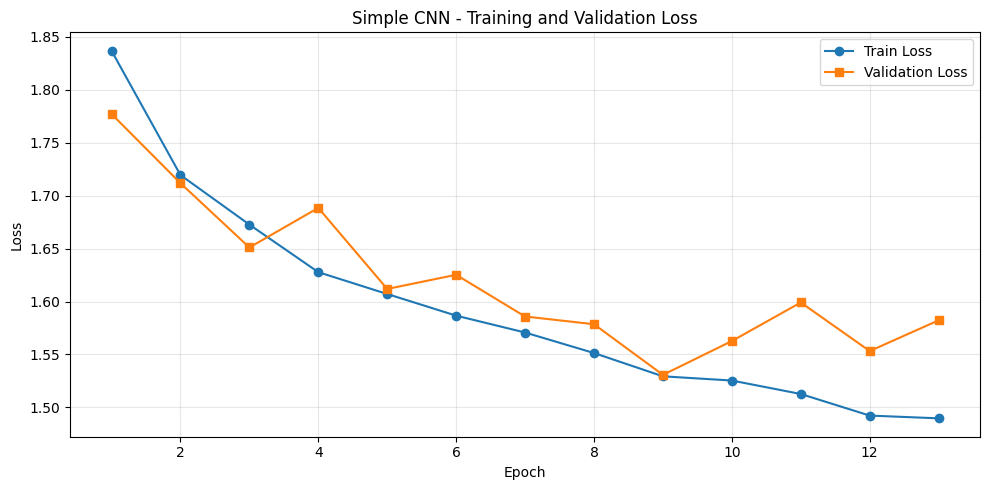

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    df_history["epoch"],
    df_history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    df_history["epoch"],
    df_history["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Simple CNN - Training and Validation Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

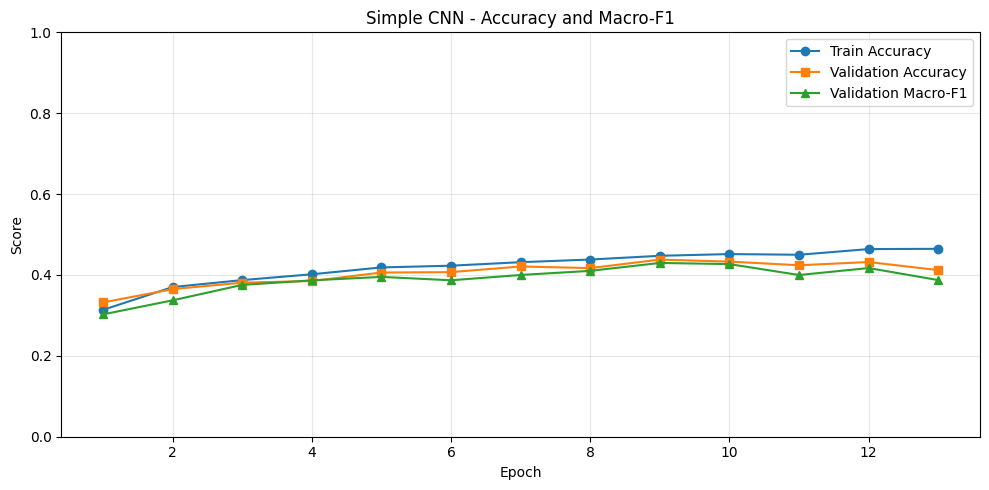

In [20]:
plt.figure(figsize=(10, 5))

plt.plot(
    df_history["epoch"],
    df_history["train_accuracy"],
    label="Train Accuracy",
    marker="o"
)

plt.plot(
    df_history["epoch"],
    df_history["val_accuracy"],
    label="Validation Accuracy",
    marker="s"
)

plt.plot(
    df_history["epoch"],
    df_history["val_macro_f1"],
    label="Validation Macro-F1",
    marker="^"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Simple CNN - Accuracy and Macro-F1")

plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
import torch
from pathlib import Path

device = torch.device("cuda")

PROJECT_DIR = Path("/content/drive/MyDrive/nhận diện")

best_model_path = (
    PROJECT_DIR / "checkpoints" / "simple_cnn_best.pt"
)

assert best_model_path.exists(), "Không tìm thấy checkpoint!"

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

assert checkpoint["class_names"] == target_classes, (
    "Thứ tự nhãn không khớp với checkpoint!"
)

best_model = SimpleCNN(
    num_classes=8
).to(device)

best_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_model.eval()

print("MODEL LOADED SUCCESSFULLY")
print("Best Epoch:", checkpoint["epoch"])
print(
    "Best Validation Macro-F1:",
    checkpoint["val_macro_f1"]
)

MODEL LOADED SUCCESSFULLY
Best Epoch: 9
Best Validation Macro-F1: 0.42974794447094183


In [22]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)
import pandas as pd

all_true = []
all_pred = []

best_model.eval()

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(device, non_blocking=True)

        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        all_true.extend(labels.tolist())
        all_pred.extend(predictions.cpu().tolist())

report = classification_report(
    all_true,
    all_pred,
    labels=list(range(8)),
    target_names=target_classes,
    output_dict=True,
    zero_division=0
)

df_report = pd.DataFrame(report).T

display(df_report.round(4))

,precision,recall,f1-score,support
metal,0.2597,0.160,0.1980,125.000
plastic,0.4609,0.472,0.4664,125.000
glass,0.4746,0.448,0.4609,125.000
ceramic,0.3301,0.272,0.2982,125.000
wood,0.4876,0.472,0.4797,125.000
stone,0.4008,0.760,0.5249,125.000
brick,0.8413,0.424,0.5638,125.000
tile,0.4052,0.496,0.4460,125.000
accuracy,0.4380,0.438,0.4380,0.438
macro avg,0.4575,0.438,0.4297,1000.000


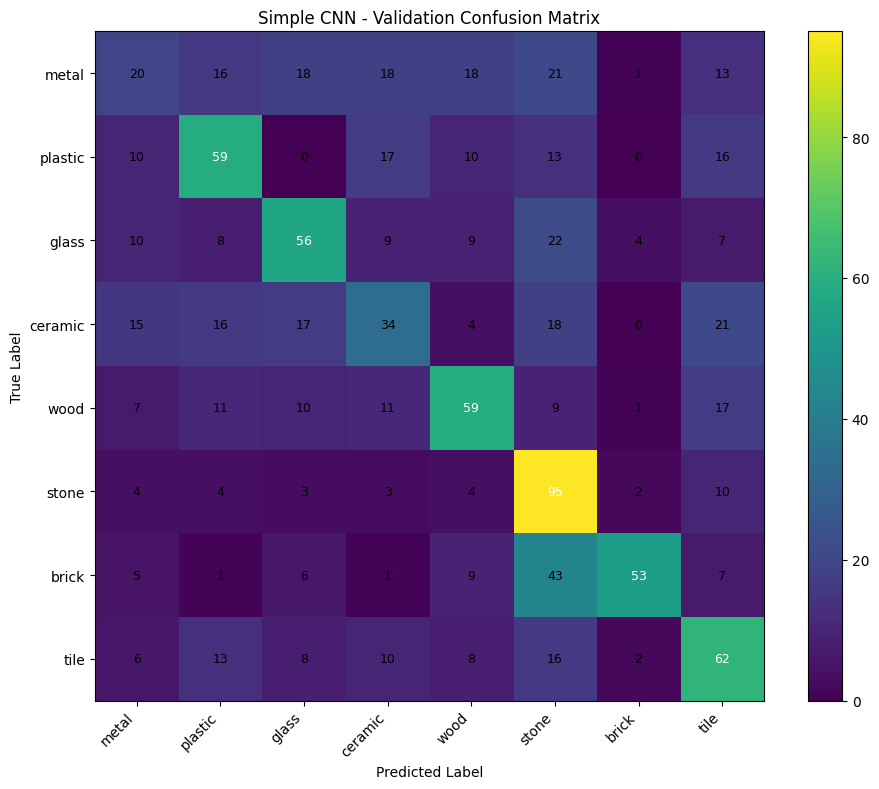

In [23]:
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(
    all_true,
    all_pred,
    labels=list(range(8))
)

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(cm)

ax.set_xticks(range(8))
ax.set_yticks(range(8))

ax.set_xticklabels(target_classes, rotation=45, ha="right")
ax.set_yticklabels(target_classes)

ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title("Simple CNN - Validation Confusion Matrix")

for i in range(8):
    for j in range(8):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=9,
            color="white" if cm[i, j] > cm.max()/2 else "black"
        )

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [24]:
result_dir = PROJECT_DIR / "results"
result_dir.mkdir(parents=True, exist_ok=True)

df_report.to_csv(
    result_dir / "simple_cnn_classification_report.csv",
    encoding="utf-8-sig"
)

pd.DataFrame(
    cm,
    index=target_classes,
    columns=target_classes
).to_csv(
    result_dir / "simple_cnn_confusion_matrix.csv",
    encoding="utf-8-sig"
)

fig.savefig(
    result_dir / "simple_cnn_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

print("Đã lưu kết quả đánh giá Validation!")

Đã lưu kết quả đánh giá Validation!


In [25]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import random
from pathlib import Path

from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert device.type == "cuda", "Chưa có GPU!"
assert len(target_classes) == 8
assert len(train_ds) == 17000
assert len(val_ds) == 1000

# Tải trọng số pretrained trên ImageNet
weights = MobileNet_V3_Small_Weights.DEFAULT

mobile_model = mobilenet_v3_small(weights=weights)

# Đóng băng backbone
for param in mobile_model.features.parameters():
    param.requires_grad = False

# Thay lớp phân loại cuối
in_features = mobile_model.classifier[-1].in_features

mobile_model.classifier[-1] = nn.Linear(
    in_features, 8
)

mobile_model = mobile_model.to(device)

total_params = sum(
    p.numel() for p in mobile_model.parameters()
)

trainable_params = sum(
    p.numel() for p in mobile_model.parameters()
    if p.requires_grad
)

print("MODEL: MobileNetV3-Small")
print("DEVICE:", device)
print("TOTAL PARAMETERS:", f"{total_params:,}")
print("TRAINABLE PARAMETERS:", f"{trainable_params:,}")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 29.2MB/s]

MODEL: MobileNetV3-Small
DEVICE: cuda
TOTAL PARAMETERS: 1,526,056
TRAINABLE PARAMETERS: 599,048


In [26]:
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm
import time

mobile_criterion = nn.CrossEntropyLoss()

mobile_optimizer = optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        mobile_model.parameters()
    ),
    lr=0.001,
    weight_decay=0.0001
)

MAX_EPOCHS = 12
PATIENCE = 4

PROJECT_DIR = Path("/content/drive/MyDrive/nhận diện")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULT_DIR = PROJECT_DIR / "results"

assert Path("/content/drive/MyDrive").is_dir(), (
    "Hãy kết nối Google Drive trước!"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("Loss: CrossEntropyLoss")
print("Optimizer: AdamW")
print("Max Epochs:", MAX_EPOCHS)
print("Early Stopping:", PATIENCE)
print("READY!")

Loss: CrossEntropyLoss
Optimizer: AdamW
Max Epochs: 12
Early Stopping: 4
READY!


In [27]:
def run_mobile_epoch(loader, training=False):

    mobile_model.train(training)

    # Giữ BatchNorm của backbone ở chế độ đánh giá
    # khi phần trích xuất đặc trưng đang bị đóng băng.
    if training:
        mobile_model.features.eval()

    loss_sum = 0.0
    all_true = []
    all_pred = []

    for images, labels in tqdm(
        loader,
        desc="Training" if training else "Validation",
        leave=False
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            mobile_optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = mobile_model(images)

            loss = mobile_criterion(outputs, labels)

            if training:
                loss.backward()
                mobile_optimizer.step()

        predictions = outputs.argmax(dim=1)

        loss_sum += loss.item() * labels.size(0)

        all_true.extend(labels.detach().cpu().tolist())
        all_pred.extend(predictions.detach().cpu().tolist())

    avg_loss = loss_sum / len(loader.dataset)

    accuracy = accuracy_score(all_true, all_pred)

    macro_f1 = f1_score(
        all_true,
        all_pred,
        labels=list(range(8)),
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1

print("MobileNetV3 Training Function: READY")

MobileNetV3 Training Function: READY


In [28]:
mobile_history = []

best_mobile_f1 = -1.0
best_mobile_epoch = 0
patience_counter = 0

for epoch in range(1, MAX_EPOCHS + 1):

    start = time.perf_counter()

    train_loss, train_acc, train_f1 = run_mobile_epoch(
        train_loader, training=True
    )

    val_loss, val_acc, val_f1 = run_mobile_epoch(
        val_loader, training=False
    )

    elapsed = time.perf_counter() - start

    mobile_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "time_seconds": elapsed
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    # Chọn mô hình tốt nhất bằng Validation
    if val_f1 > best_mobile_f1 + 1e-4:

        best_mobile_f1 = val_f1
        best_mobile_epoch = epoch
        patience_counter = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": mobile_model.state_dict(),
            "class_names": target_classes,
            "val_macro_f1": val_f1,
            "architecture": "mobilenet_v3_small",
            "training_stage": "feature_extraction"
        }, CHECKPOINT_DIR / "mobilenetv3_best.pt")

        print("  -> SAVED BEST MODEL")

    else:
        patience_counter += 1

    # Lưu tiến độ sau mỗi epoch
    torch.save({
        "epoch": epoch,
        "model_state_dict": mobile_model.state_dict(),
        "optimizer_state_dict": mobile_optimizer.state_dict(),
        "best_f1": best_mobile_f1,
        "best_epoch": best_mobile_epoch,
        "patience_counter": patience_counter,
        "history": mobile_history,
        "class_names": target_classes
    }, CHECKPOINT_DIR / "mobilenetv3_last.pt")

    pd.DataFrame(mobile_history).to_csv(
        RESULT_DIR / "mobilenetv3_history.csv",
        index=False
    )

    if patience_counter >= PATIENCE:
        print("EARLY STOPPING ACTIVATED")
        break

df_mobile_history = pd.DataFrame(mobile_history)

print("\nTRAINING COMPLETED")
print("Best Epoch:", best_mobile_epoch)
print("Best Validation Macro-F1:", round(best_mobile_f1, 4))

display(df_mobile_history)

Training:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7eb05c4858a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7eb05c4858a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
if w.is_alive():    
Exception ignored

Epoch 01 | Train Loss: 1.0475 | Val Loss: 0.9914 | Train Acc: 0.6281 | Val Acc: 0.6320 | Val F1: 0.6328
  -> SAVED BEST MODEL


Training:   0%|          | 0/532 [00:00<?, ?it/s]

...

Training:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7eb05c4858a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7eb05c4858a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 07 | Train Loss: 0.3681 | Val Loss: 1.1178 | Train Acc: 0.8695 | Val Acc: 0.6670 | Val F1: 0.6653
EARLY STOPPING ACTIVATED

TRAINING COMPLETED
Best Epoch: 3
Best Validation Macro-F1: 0.6655


,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,time_seconds
0,1,1.047487,0.628118,0.627650,0.991382,0.632,0.632788,93.793820
1,2,0.858852,0.697412,0.697147,0.971045,0.650,0.649831,91.244602
2,3,0.746294,0.737588,0.737259,0.938520,0.666,0.665511,89.386782
3,4,0.642332,0.772118,0.771835,0.980270,0.646,0.646055,88.142263
4,5,0.544606,0.805824,0.805636,1.038213,0.637,0.638722,88.144696
5,6,0.456039,0.841529,0.841395,1.102331,0.628,0.629589,87.279480
6,7,0.368113,0.869529,0.869450,1.117765,0.667,0.665307,87.831666


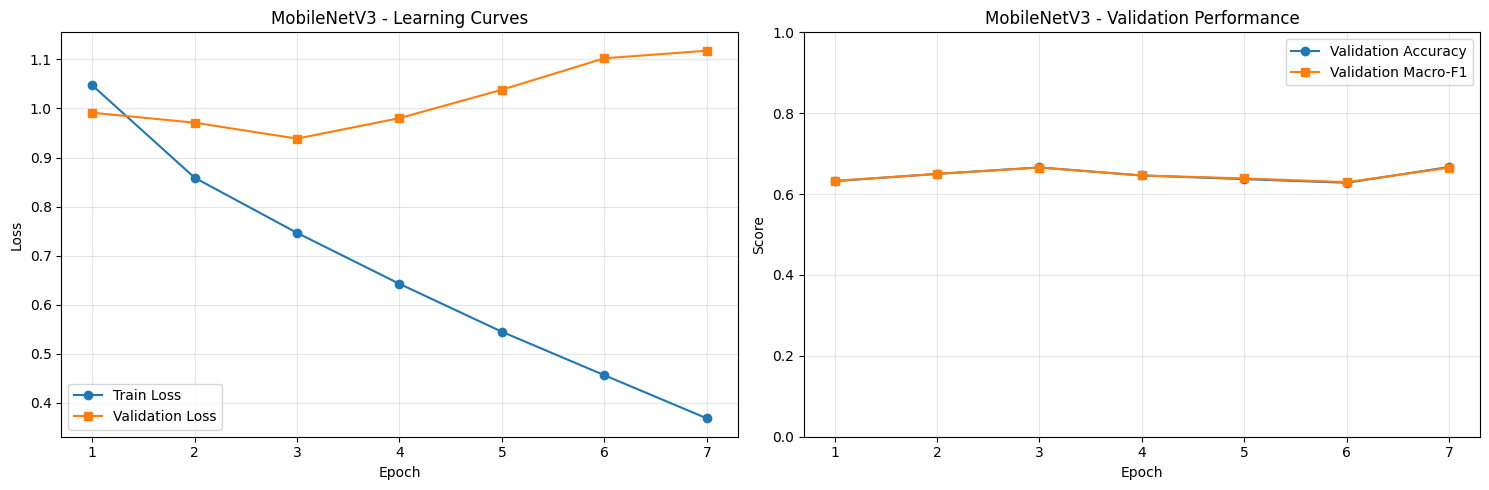

In [29]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Biểu đồ Loss
axes[0].plot(
    df_mobile_history["epoch"],
    df_mobile_history["train_loss"],
    marker="o",
    label="Train Loss"
)

axes[0].plot(
    df_mobile_history["epoch"],
    df_mobile_history["val_loss"],
    marker="s",
    label="Validation Loss"
)

axes[0].set_title("MobileNetV3 - Learning Curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Biểu đồ Accuracy và F1
axes[1].plot(
    df_mobile_history["epoch"],
    df_mobile_history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

axes[1].plot(
    df_mobile_history["epoch"],
    df_mobile_history["val_macro_f1"],
    marker="s",
    label="Validation Macro-F1"
)

axes[1].set_title("MobileNetV3 - Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "mobilenetv3_training_curves.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [30]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DataLoader đã được cấu hình lại!")

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoader đã được cấu hình lại!
Train batches: 532
Validation batches: 32
Test batches: 63


In [31]:
import torch
import torch.nn as nn
from pathlib import Path
from torchvision.models import mobilenet_v3_small

device = torch.device("cuda")

PROJECT_DIR = Path("/content/drive/MyDrive/nhận diện")

best_path = (
    PROJECT_DIR / "checkpoints" / "mobilenetv3_best.pt"
)

assert best_path.exists(), "Không tìm thấy checkpoint!"

checkpoint = torch.load(
    best_path,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["class_names"] == target_classes

# Khởi tạo đúng kiến trúc
best_mobile = mobilenet_v3_small(weights=None)

in_features = best_mobile.classifier[-1].in_features

best_mobile.classifier[-1] = nn.Linear(
    in_features,
    8
)

# Nạp trọng số đã huấn luyện
best_mobile.load_state_dict(
    checkpoint["model_state_dict"]
)

best_mobile = best_mobile.to(device)
best_mobile.eval()

print("BEST MODEL LOADED!")
print("Best Epoch:", checkpoint["epoch"])
print("Best Macro-F1:", checkpoint["val_macro_f1"])

BEST MODEL LOADED!
Best Epoch: 3
Best Macro-F1: 0.665510814243448


In [32]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

y_true = []
y_pred = []

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = best_mobile(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

# Báo cáo chi tiết
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(8)),
    target_names=target_classes,
    output_dict=True,
    zero_division=0
)

df_mobile_report = pd.DataFrame(report).T

print("MOBILENETV3 - VALIDATION RESULTS")
print("=" * 50)

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Macro-F1:", f1_score(
    y_true, y_pred,
    labels=list(range(8)),
    average="macro"
))

display(df_mobile_report.round(4))

MOBILENETV3 - VALIDATION RESULTS
Accuracy: 0.666
Macro-F1: 0.665510814243448


,precision,recall,f1-score,support
metal,0.5932,0.560,0.5761,125.000
plastic,0.6107,0.640,0.6250,125.000
glass,0.6486,0.576,0.6102,125.000
ceramic,0.6090,0.648,0.6279,125.000
wood,0.6260,0.656,0.6406,125.000
stone,0.7863,0.736,0.7603,125.000
brick,0.7537,0.808,0.7799,125.000
tile,0.7040,0.704,0.7040,125.000
accuracy,0.6660,0.666,0.6660,0.666
macro avg,0.6664,0.666,0.6655,1000.000


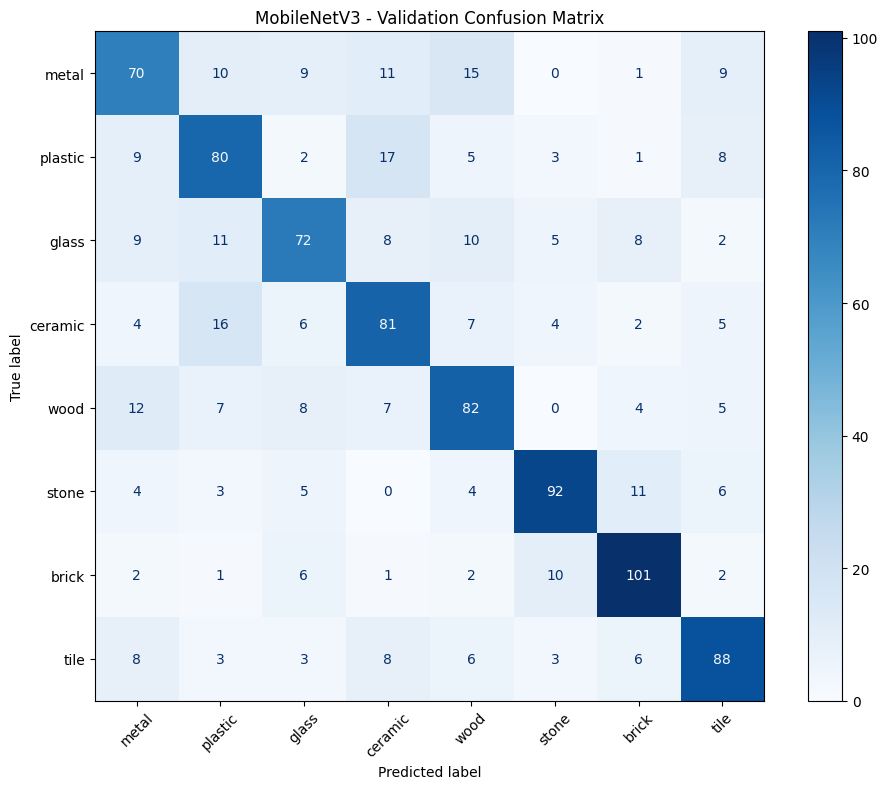

Đã lưu kết quả lên Google Drive!


In [33]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(8))
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("MobileNetV3 - Validation Confusion Matrix")
plt.tight_layout()

RESULT_DIR = PROJECT_DIR / "results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    RESULT_DIR / "mobilenetv3_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

df_mobile_report.to_csv(
    RESULT_DIR / "mobilenetv3_classification_report.csv",
    encoding="utf-8-sig"
)

plt.show()

print("Đã lưu kết quả lên Google Drive!")

In [34]:
import torch
import torch.nn as nn
import torch.optim as optim
import random
import numpy as np

from pathlib import Path
from torchvision.models import mobilenet_v3_small
from torch.utils.data import DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda")

PROJECT_DIR = Path("/content/drive/MyDrive/nhận diện")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULT_DIR = PROJECT_DIR / "results"

assert torch.cuda.is_available()
assert len(target_classes) == 8

# Tránh lỗi multiprocessing đã gặp
train_loader = DataLoader(
    train_ds, batch_size=32,
    shuffle=True, num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds, batch_size=32,
    shuffle=False, num_workers=0,
    pin_memory=True
)

# Tải checkpoint tốt nhất ở giai đoạn trước
checkpoint = torch.load(
    CHECKPOINT_DIR / "mobilenetv3_best.pt",
    map_location="cpu",
    weights_only=True
)

assert checkpoint["class_names"] == target_classes

ft_model = mobilenet_v3_small(weights=None)

in_features = ft_model.classifier[-1].in_features
ft_model.classifier[-1] = nn.Linear(in_features, 8)

ft_model.load_state_dict(
    checkpoint["model_state_dict"]
)

# Đóng băng toàn bộ backbone trước
for p in ft_model.features.parameters():
    p.requires_grad = False

# Chỉ mở hai khối cuối của backbone
for p in ft_model.features[-2:].parameters():
    p.requires_grad = True

# Classifier vẫn được huấn luyện
for p in ft_model.classifier.parameters():
    p.requires_grad = True

ft_model = ft_model.to(device)

ft_optimizer = optim.AdamW([
    {
        "params": ft_model.features[-2:].parameters(),
        "lr": 1e-5
    },
    {
        "params": ft_model.classifier.parameters(),
        "lr": 1e-4
    }
], weight_decay=1e-4)

ft_criterion = nn.CrossEntropyLoss()

trainable = sum(
    p.numel() for p in ft_model.parameters()
    if p.requires_grad
)

print("PROJECT: nhận diện")
print("MODEL: MobileNetV3 Fine-tuning")
print("Trainable parameters:", f"{trainable:,}")
print("Checkpoint Epoch:", checkpoint["epoch"])
print("READY!")

PROJECT: nhận diện
MODEL: MobileNetV3 Fine-tuning
Trainable parameters: 949,592
Checkpoint Epoch: 3
READY!


In [35]:
from sklearn.metrics import f1_score, accuracy_score
from tqdm.auto import tqdm

def run_finetune_epoch(loader, training=False):

    ft_model.train(training)

    # Giữ thống kê BatchNorm của backbone cố định
    # nhưng vẫn cho phép tính gradient tại các khối mở.
    if training:
        ft_model.features.eval()

    total_loss = 0.0
    all_true = []
    all_pred = []

    for images, labels in tqdm(
        loader,
        desc="Fine-tune" if training else "Validation",
        leave=False
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            ft_optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = ft_model(images)
            loss = ft_criterion(outputs, labels)

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    filter(
                        lambda p: p.requires_grad,
                        ft_model.parameters()
                    ),
                    max_norm=1.0
                )
                ft_optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        all_true.extend(labels.detach().cpu().tolist())
        all_pred.extend(predictions.detach().cpu().tolist())

    loss_value = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_true, all_pred)

    macro_f1 = f1_score(
        all_true,
        all_pred,
        labels=list(range(8)),
        average="macro",
        zero_division=0
    )

    return loss_value, accuracy, macro_f1

print("FINE-TUNING FUNCTION: READY")

FINE-TUNING FUNCTION: READY


In [36]:
import time
import pandas as pd

MAX_EPOCHS = 8
PATIENCE = 3

baseline_f1 = float(checkpoint["val_macro_f1"])

best_ft_f1 = baseline_f1
best_ft_epoch = 0
patience_counter = 0

ft_history = []

for epoch in range(1, MAX_EPOCHS + 1):

    start = time.perf_counter()

    tr_loss, tr_acc, tr_f1 = run_finetune_epoch(
        train_loader, training=True
    )

    vl_loss, vl_acc, vl_f1 = run_finetune_epoch(
        val_loader, training=False
    )

    elapsed = time.perf_counter() - start

    ft_history.append({
        "epoch": epoch,
        "train_loss": tr_loss,
        "train_accuracy": tr_acc,
        "train_macro_f1": tr_f1,
        "val_loss": vl_loss,
        "val_accuracy": vl_acc,
        "val_macro_f1": vl_f1,
        "time_seconds": elapsed
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {tr_loss:.4f} | "
        f"Val Loss: {vl_loss:.4f} | "
        f"Train Acc: {tr_acc:.4f} | "
        f"Val Acc: {vl_acc:.4f} | "
        f"Val F1: {vl_f1:.4f}"
    )

    if vl_f1 > best_ft_f1 + 1e-4:

        best_ft_f1 = vl_f1
        best_ft_epoch = epoch
        patience_counter = 0

        torch.save({
            "model_state_dict": ft_model.state_dict(),
            "epoch": epoch,
            "class_names": target_classes,
            "val_macro_f1": vl_f1,
            "architecture": "mobilenet_v3_small",
            "training_stage": "partial_fine_tuning"
        }, CHECKPOINT_DIR / "mobilenetv3_finetune_best.pt")

        print("  -> NEW BEST FINE-TUNED MODEL SAVED")

    else:
        patience_counter += 1

    pd.DataFrame(ft_history).to_csv(
        RESULT_DIR / "mobilenetv3_finetune_history.csv",
        index=False
    )

    torch.save({
        "epoch": epoch,
        "model_state_dict": ft_model.state_dict(),
        "optimizer_state_dict": ft_optimizer.state_dict(),
        "best_f1": best_ft_f1,
        "best_epoch": best_ft_epoch,
        "patience_counter": patience_counter,
        "history": ft_history
    }, CHECKPOINT_DIR / "mobilenetv3_finetune_last.pt")

    if patience_counter >= PATIENCE:
        print("EARLY STOPPING ACTIVATED")
        break

df_ft_history = pd.DataFrame(ft_history)

print("\nFINE-TUNING COMPLETED")
print("Original Validation Macro-F1:", round(baseline_f1, 4))
print("Best Fine-tuned/Retained F1:", round(best_ft_f1, 4))

if best_ft_epoch == 0:
    print("Không cải thiện. Giữ checkpoint ban đầu.")
else:
    print("Best Fine-tuning Epoch:", best_ft_epoch)

display(df_ft_history)

Fine-tune:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.5606 | Val Loss: 0.9070 | Train Acc: 0.8045 | Val Acc: 0.6750 | Val F1: 0.6741
  -> NEW BEST FINE-TUNED MODEL SAVED


Fine-tune:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

...

Epoch 07 | Train Loss: 0.3588 | Val Loss: 0.9615 | Train Acc: 0.8834 | Val Acc: 0.6770 | Val F1: 0.6770


Fine-tune:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 08 | Train Loss: 0.3348 | Val Loss: 0.9693 | Train Acc: 0.8896 | Val Acc: 0.6810 | Val F1: 0.6806

FINE-TUNING COMPLETED
Original Validation Macro-F1: 0.6655
Best Fine-tuned/Retained F1: 0.6911
Best Fine-tuning Epoch: 6


,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,time_seconds
0,1,0.560581,0.804529,0.804268,0.907022,0.675,0.674136,105.616153
1,2,0.499393,0.830000,0.829805,0.912180,0.675,0.675503,103.645887
2,3,0.464996,0.841000,0.840819,0.918606,0.681,0.679781,103.624584
3,4,0.433448,0.854824,0.854669,0.929379,0.680,0.679814,102.662852
4,5,0.406785,0.861000,0.860823,0.937898,0.682,0.681970,103.020637
5,6,0.383267,0.871765,0.871628,0.953828,0.692,0.691128,102.933621
6,7,0.358848,0.883353,0.883224,0.961532,0.677,0.676964,105.364592
7,8,0.334783,0.889647,0.889511,0.969336,0.681,0.680568,105.170636


In [37]:
import torch
import torch.nn as nn
from pathlib import Path
from torchvision.models import mobilenet_v3_small

device = torch.device("cuda")

PROJECT_DIR = Path("/content/drive/MyDrive/nhận diện")

checkpoint_path = (
    PROJECT_DIR / "checkpoints" /
    "mobilenetv3_finetune_best.pt"
)

assert checkpoint_path.exists(), "Không tìm thấy checkpoint!"

ckpt = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert ckpt["class_names"] == target_classes

ft_best = mobilenet_v3_small(weights=None)

in_features = ft_best.classifier[-1].in_features
ft_best.classifier[-1] = nn.Linear(in_features, 8)

ft_best.load_state_dict(ckpt["model_state_dict"])

ft_best = ft_best.to(device)
ft_best.eval()

print("MODEL LOADED SUCCESSFULLY")
print("Best Epoch:", ckpt["epoch"])
print("Best Validation Macro-F1:", ckpt["val_macro_f1"])

MODEL LOADED SUCCESSFULLY
Best Epoch: 6
Best Validation Macro-F1: 0.6911277369291099


In [38]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

y_true_ft = []
y_pred_ft = []

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = ft_best(images)
        predictions = outputs.argmax(dim=1)

        y_true_ft.extend(labels.tolist())
        y_pred_ft.extend(predictions.cpu().tolist())

report_ft = classification_report(
    y_true_ft,
    y_pred_ft,
    labels=list(range(8)),
    target_names=target_classes,
    output_dict=True,
    zero_division=0
)

df_ft_report = pd.DataFrame(report_ft).T

print("FINE-TUNING VALIDATION RESULTS")
print("=" * 50)

print(
    "Accuracy:",
    accuracy_score(y_true_ft, y_pred_ft)
)

print(
    "Macro-F1:",
    f1_score(
        y_true_ft,
        y_pred_ft,
        labels=list(range(8)),
        average="macro",
        zero_division=0
    )
)

display(df_ft_report.round(4))

FINE-TUNING VALIDATION RESULTS
Accuracy: 0.692
Macro-F1: 0.6911277369291099


,precision,recall,f1-score,support
metal,0.6167,0.592,0.6041,125.000
plastic,0.6957,0.640,0.6667,125.000
glass,0.6783,0.624,0.6500,125.000
ceramic,0.6519,0.704,0.6769,125.000
wood,0.6905,0.696,0.6932,125.000
stone,0.8148,0.704,0.7554,125.000
brick,0.7241,0.840,0.7778,125.000
tile,0.6765,0.736,0.7050,125.000
accuracy,0.6920,0.692,0.6920,0.692
macro avg,0.6935,0.692,0.6911,1000.000


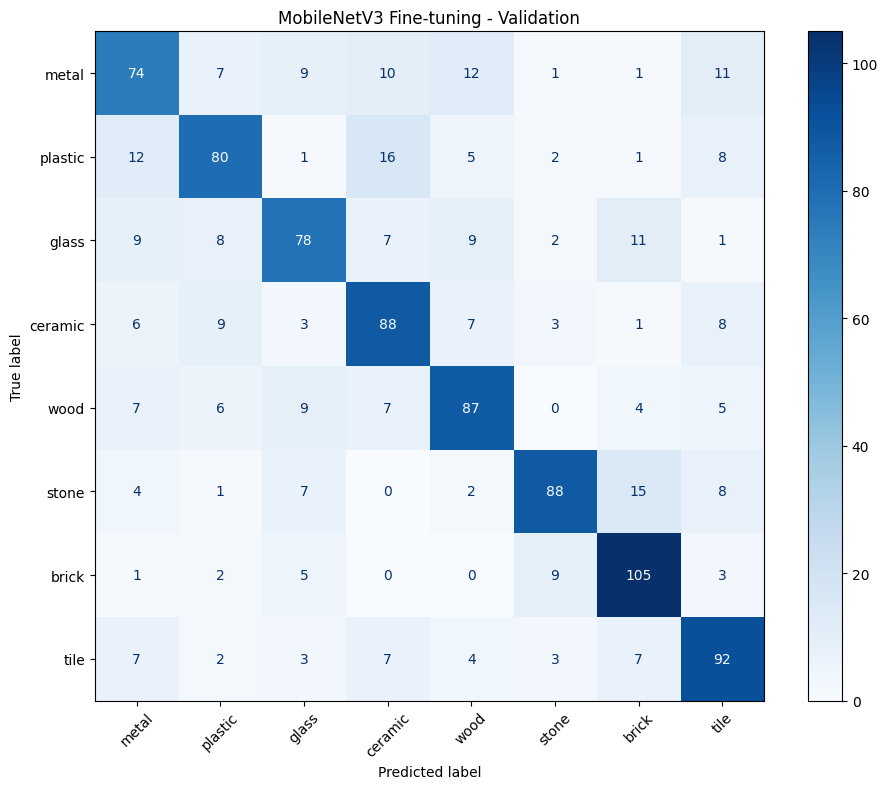

In [39]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm_ft = confusion_matrix(
    y_true_ft,
    y_pred_ft,
    labels=list(range(8))
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ft,
    display_labels=target_classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("MobileNetV3 Fine-tuning - Validation")
plt.tight_layout()
plt.show()

In [40]:
result_dir = PROJECT_DIR / "results"
result_dir.mkdir(parents=True, exist_ok=True)

df_ft_report.to_csv(
    result_dir / "mobilenetv3_finetune_report.csv",
    encoding="utf-8-sig"
)

pd.DataFrame(
    cm_ft,
    index=target_classes,
    columns=target_classes
).to_csv(
    result_dir / "mobilenetv3_finetune_confusion_matrix.csv",
    encoding="utf-8-sig"
)

fig.savefig(
    result_dir / "mobilenetv3_finetune_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

print("Đã lưu báo cáo Fine-tuning!")

Đã lưu báo cáo Fine-tuning!


In [41]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import random

from pathlib import Path
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda")

assert torch.cuda.is_available()
assert len(target_classes) == 8
assert len(train_ds) == 17000
assert len(val_ds) == 1000

# Tải mô hình pretrained
weights = EfficientNet_B0_Weights.DEFAULT

eff_model = efficientnet_b0(weights=weights)

# Đóng băng backbone
for param in eff_model.features.parameters():
    param.requires_grad = False

# Thay lớp phân loại thành 8 lớp
in_features = eff_model.classifier[-1].in_features

eff_model.classifier[-1] = nn.Linear(
    in_features,
    8
)

eff_model = eff_model.to(device)

total_params = sum(
    p.numel() for p in eff_model.parameters()
)

trainable_params = sum(
    p.numel() for p in eff_model.parameters()
    if p.requires_grad
)

print("MODEL: EfficientNet-B0")
print("DEVICE:", device)
print("TOTAL PARAMETERS:", f"{total_params:,}")
print("TRAINABLE PARAMETERS:", f"{trainable_params:,}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 99.9MB/s]


MODEL: EfficientNet-B0
DEVICE: cuda
TOTAL PARAMETERS: 4,017,796
TRAINABLE PARAMETERS: 10,248


In [42]:
eff_model.eval()

images, labels = next(iter(train_loader))
sample_images = images[:4].to(device)

with torch.inference_mode():
    outputs = eff_model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)

assert outputs.shape == (4, 8)
assert torch.isfinite(outputs).all()

print("EFFICIENTNET FORWARD TEST: PASSED")

Input shape: torch.Size([4, 3, 224, 224])
Output shape: torch.Size([4, 8])
EFFICIENTNET FORWARD TEST: PASSED


In [43]:
import time
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score

PROJECT_DIR = Path("/content/drive/MyDrive/nhận diện")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULT_DIR = PROJECT_DIR / "results"

assert Path("/content/drive/MyDrive").is_dir(), (
    "Google Drive chưa được kết nối!"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

eff_criterion = nn.CrossEntropyLoss()

eff_optimizer = optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        eff_model.parameters()
    ),
    lr=0.001,
    weight_decay=0.0001
)

def run_efficientnet_epoch(loader, training=False):

    eff_model.train(training)

    # Cố định BatchNorm của frozen backbone
    if training:
        eff_model.features.eval()

    total_loss = 0.0
    y_true = []
    y_pred = []

    for images, labels in tqdm(
        loader,
        desc="Train" if training else "Validation",
        leave=False
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            eff_optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = eff_model(images)
            loss = eff_criterion(outputs, labels)

            if training:
                loss.backward()
                eff_optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.detach().cpu().tolist())
        y_pred.extend(predictions.detach().cpu().tolist())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(y_true, y_pred)

    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=list(range(8)),
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1

print("EFFICIENTNET TRAINING FUNCTION: READY")

EFFICIENTNET TRAINING FUNCTION: READY


In [44]:
MAX_EPOCHS = 12
PATIENCE = 4

eff_history = []

best_eff_f1 = -1.0
best_eff_epoch = 0
patience_counter = 0

for epoch in range(1, MAX_EPOCHS + 1):

    start = time.perf_counter()

    tr_loss, tr_acc, tr_f1 = run_efficientnet_epoch(
        train_loader,
        training=True
    )

    vl_loss, vl_acc, vl_f1 = run_efficientnet_epoch(
        val_loader,
        training=False
    )

    elapsed = time.perf_counter() - start

    eff_history.append({
        "epoch": epoch,
        "train_loss": tr_loss,
        "train_accuracy": tr_acc,
        "train_macro_f1": tr_f1,
        "val_loss": vl_loss,
        "val_accuracy": vl_acc,
        "val_macro_f1": vl_f1,
        "time_seconds": elapsed
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {tr_loss:.4f} | "
        f"Val Loss: {vl_loss:.4f} | "
        f"Train Acc: {tr_acc:.4f} | "
        f"Val Acc: {vl_acc:.4f} | "
        f"Val F1: {vl_f1:.4f}"
    )

    if vl_f1 > best_eff_f1 + 1e-4:

        best_eff_f1 = vl_f1
        best_eff_epoch = epoch
        patience_counter = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": eff_model.state_dict(),
            "class_names": target_classes,
            "val_macro_f1": vl_f1,
            "architecture": "efficientnet_b0",
            "training_stage": "feature_extraction"
        }, CHECKPOINT_DIR / "efficientnet_b0_best.pt")

        print("  -> SAVED BEST MODEL")

    else:
        patience_counter += 1

    # Lưu lịch sử từng epoch
    pd.DataFrame(eff_history).to_csv(
        RESULT_DIR / "efficientnet_b0_history.csv",
        index=False
    )

    # Lưu checkpoint mới nhất
    torch.save({
        "epoch": epoch,
        "model_state_dict": eff_model.state_dict(),
        "optimizer_state_dict": eff_optimizer.state_dict(),
        "best_f1": best_eff_f1,
        "best_epoch": best_eff_epoch,
        "patience_counter": patience_counter,
        "history": eff_history,
        "class_names": target_classes
    }, CHECKPOINT_DIR / "efficientnet_b0_last.pt")

    if patience_counter >= PATIENCE:
        print("EARLY STOPPING ACTIVATED")
        break

df_eff_history = pd.DataFrame(eff_history)

print("\nTRAINING COMPLETED")
print("Best Epoch:", best_eff_epoch)
print("Best Validation Macro-F1:", best_eff_f1)

display(df_eff_history)

Train:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 1.0361 | Val Loss: 0.9544 | Train Acc: 0.6443 | Val Acc: 0.6670 | Val F1: 0.6680
  -> SAVED BEST MODEL


Train:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

...

Epoch 11 | Train Loss: 0.7450 | Val Loss: 0.9352 | Train Acc: 0.7332 | Val Acc: 0.6900 | Val F1: 0.6909


Train:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 12 | Train Loss: 0.7394 | Val Loss: 0.9207 | Train Acc: 0.7395 | Val Acc: 0.6840 | Val F1: 0.6829
EARLY STOPPING ACTIVATED

TRAINING COMPLETED
Best Epoch: 8
Best Validation Macro-F1: 0.6926217090167568


,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,time_seconds
0,1,1.036084,0.644294,0.643995,0.954399,0.667,0.667981,128.791192
1,2,0.863282,0.697118,0.696734,0.938883,0.662,0.661803,126.065000
2,3,0.816854,0.714471,0.714122,0.931219,0.677,0.677836,127.611577
3,4,0.800444,0.717824,0.717598,0.928224,0.691,0.690586,125.214322
4,5,0.781012,0.725765,0.725399,0.915325,0.688,0.689111,126.047983
5,6,0.770025,0.729588,0.729180,0.927613,0.686,0.686012,126.570489
6,7,0.760354,0.732882,0.732610,0.913838,0.691,0.691073,126.518644
7,8,0.755101,0.739765,0.739443,0.918494,0.693,0.692622,125.673388
8,9,0.750080,0.736941,0.736673,0.921662,0.676,0.676119,124.919816
9,10,0.744127,0.738647,0.738351,0.929446,0.681,0.680661,126.164190


In [45]:
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import efficientnet_b0

device = torch.device("cuda")

PROJECT_DIR = Path("/content/drive/MyDrive/nhận diện")

checkpoint_path = (
    PROJECT_DIR / "checkpoints" / "efficientnet_b0_best.pt"
)

assert checkpoint_path.exists(), "Không tìm thấy checkpoint!"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["class_names"] == target_classes

# Khởi tạo lại kiến trúc
best_eff = efficientnet_b0(weights=None)

in_features = best_eff.classifier[-1].in_features

best_eff.classifier[-1] = nn.Linear(
    in_features,
    8
)

# Nạp trọng số đã huấn luyện
best_eff.load_state_dict(
    checkpoint["model_state_dict"]
)

best_eff = best_eff.to(device)
best_eff.eval()

print("EFFICIENTNET BEST MODEL LOADED!")
print("Best Epoch:", checkpoint["epoch"])
print("Validation Macro-F1:", checkpoint["val_macro_f1"])

EFFICIENTNET BEST MODEL LOADED!
Best Epoch: 8
Validation Macro-F1: 0.6926217090167568


In [46]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

y_true_eff = []
y_pred_eff = []

best_eff.eval()

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(device, non_blocking=True)

        outputs = best_eff(images)
        predictions = outputs.argmax(dim=1)

        y_true_eff.extend(labels.tolist())
        y_pred_eff.extend(predictions.cpu().tolist())

report_eff = classification_report(
    y_true_eff,
    y_pred_eff,
    labels=list(range(8)),
    target_names=target_classes,
    output_dict=True,
    zero_division=0
)

df_eff_report = pd.DataFrame(report_eff).T

print("EFFICIENTNET-B0 - VALIDATION RESULTS")
print("=" * 50)

print(
    "Accuracy:",
    accuracy_score(y_true_eff, y_pred_eff)
)

print(
    "Macro-F1:",
    f1_score(
        y_true_eff,
        y_pred_eff,
        labels=list(range(8)),
        average="macro",
        zero_division=0
    )
)

display(df_eff_report.round(4))

EFFICIENTNET-B0 - VALIDATION RESULTS
Accuracy: 0.693
Macro-F1: 0.6926217090167568


,precision,recall,f1-score,support
metal,0.6000,0.552,0.5750,125.000
plastic,0.6170,0.696,0.6541,125.000
glass,0.7436,0.696,0.7190,125.000
ceramic,0.7168,0.648,0.6807,125.000
wood,0.6423,0.704,0.6718,125.000
stone,0.7478,0.688,0.7167,125.000
brick,0.7846,0.816,0.8000,125.000
tile,0.7045,0.744,0.7237,125.000
accuracy,0.6930,0.693,0.6930,0.693
macro avg,0.6946,0.693,0.6926,1000.000


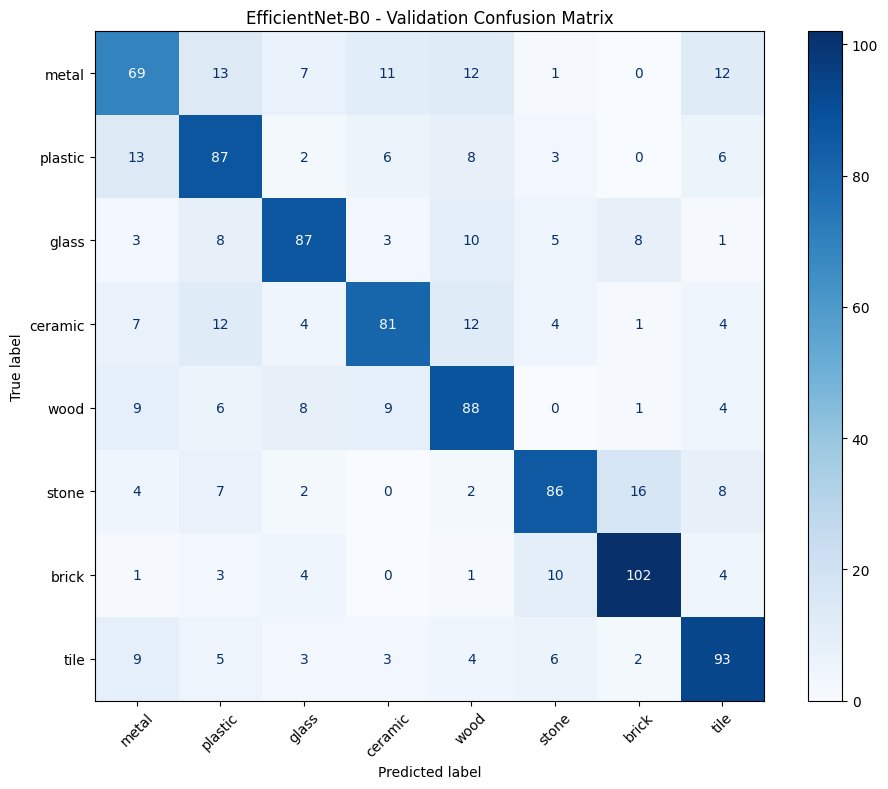

In [47]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm_eff = confusion_matrix(
    y_true_eff,
    y_pred_eff,
    labels=list(range(8))
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_eff,
    display_labels=target_classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title("EfficientNet-B0 - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [48]:
RESULT_DIR = PROJECT_DIR / "results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

df_eff_report.to_csv(
    RESULT_DIR / "efficientnet_b0_report.csv",
    encoding="utf-8-sig"
)

pd.DataFrame(
    cm_eff,
    index=target_classes,
    columns=target_classes
).to_csv(
    RESULT_DIR / "efficientnet_b0_confusion_matrix.csv",
    encoding="utf-8-sig"
)

fig.savefig(
    RESULT_DIR / "efficientnet_b0_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

print("Đã lưu toàn bộ kết quả EfficientNet-B0!")

Đã lưu toàn bộ kết quả EfficientNet-B0!


In [49]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random

from pathlib import Path
from torchvision.models import efficientnet_b0
from torch.utils.data import DataLoader

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda")

PROJECT_DIR = Path("/content/drive/MyDrive/nhận diện")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULT_DIR = PROJECT_DIR / "results"

assert torch.cuda.is_available()
assert CHECKPOINT_DIR.exists()
assert len(target_classes) == 8

# Tải checkpoint EfficientNet tốt nhất
checkpoint = torch.load(
    CHECKPOINT_DIR / "efficientnet_b0_best.pt",
    map_location="cpu",
    weights_only=True
)

assert checkpoint["class_names"] == target_classes

# Khởi tạo đúng kiến trúc
ft_eff = efficientnet_b0(weights=None)

in_features = ft_eff.classifier[-1].in_features

ft_eff.classifier[-1] = nn.Linear(in_features, 8)

# Nạp trọng số đã huấn luyện
ft_eff.load_state_dict(
    checkpoint["model_state_dict"]
)

# Đóng băng toàn bộ backbone
for param in ft_eff.features.parameters():
    param.requires_grad = False

# Mở hai module cuối
for param in ft_eff.features[-2:].parameters():
    param.requires_grad = True

# Cho phép classifier tiếp tục học
for param in ft_eff.classifier.parameters():
    param.requires_grad = True

ft_eff = ft_eff.to(device)

# Kiểm tra số tham số
total_params = sum(
    p.numel() for p in ft_eff.parameters()
)

trainable_params = sum(
    p.numel() for p in ft_eff.parameters()
    if p.requires_grad
)

print("PROJECT: nhận diện")
print("MODEL: EfficientNet-B0 Fine-tuning")
print("Checkpoint Epoch:", checkpoint["epoch"])
print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("READY FOR FINE-TUNING!")

PROJECT: nhận diện
MODEL: EfficientNet-B0 Fine-tuning
Checkpoint Epoch: 8
Total Parameters: 4017796
Trainable Parameters: 1139640
READY FOR FINE-TUNING!


In [50]:
train_loader = DataLoader(
    train_ds,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

ft_eff_criterion = nn.CrossEntropyLoss()

ft_eff_optimizer = optim.AdamW(
    [
        {
            "params": ft_eff.features[-2:].parameters(),
            "lr": 1e-5
        },
        {
            "params": ft_eff.classifier.parameters(),
            "lr": 1e-4
        }
    ],
    weight_decay=1e-4
)

print("DataLoader và Optimizer đã sẵn sàng!")

DataLoader và Optimizer đã sẵn sàng!


In [51]:
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

def run_ft_eff_epoch(loader, training=False):

    ft_eff.train(training)

    # Giữ thống kê BatchNorm backbone cố định.
    # eval() không ngăn gradient tại các tầng đã mở.
    if training:
        ft_eff.features.eval()

    total_loss = 0.0
    y_true = []
    y_pred = []

    for images, labels in tqdm(
        loader,
        desc="Training" if training else "Validation",
        leave=False
    ):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if training:
            ft_eff_optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            outputs = ft_eff(images)
            loss = ft_eff_criterion(outputs, labels)

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    [
                        p for p in ft_eff.parameters()
                        if p.requires_grad
                    ],
                    max_norm=1.0
                )

                ft_eff_optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.detach().cpu().tolist())
        y_pred.extend(predictions.detach().cpu().tolist())

    avg_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(y_true, y_pred)

    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=list(range(8)),
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1

print("TRAINING FUNCTION: READY")

TRAINING FUNCTION: READY


In [52]:
import time
import pandas as pd

MAX_EPOCHS = 8
PATIENCE = 3

original_f1 = float(checkpoint["val_macro_f1"])

best_ft_f1 = original_f1
best_ft_epoch = 0

patience_counter = 0
ft_eff_history = []

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

for epoch in range(1, MAX_EPOCHS + 1):

    start = time.perf_counter()

    train_loss, train_acc, train_f1 = run_ft_eff_epoch(
        train_loader,
        training=True
    )

    val_loss, val_acc, val_f1 = run_ft_eff_epoch(
        val_loader,
        training=False
    )

    elapsed = time.perf_counter() - start

    ft_eff_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "time_seconds": elapsed
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    # Chỉ lưu BEST khi vượt checkpoint gốc
    if val_f1 > best_ft_f1 + 1e-4:

        best_ft_f1 = val_f1
        best_ft_epoch = epoch
        patience_counter = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": ft_eff.state_dict(),
            "class_names": target_classes,
            "val_macro_f1": val_f1,
            "architecture": "efficientnet_b0",
            "training_stage": "partial_fine_tuning"
        }, CHECKPOINT_DIR / "efficientnet_b0_finetune_best.pt")

        print("  -> NEW BEST MODEL SAVED")

    else:
        patience_counter += 1

    # Lưu lịch sử
    pd.DataFrame(ft_eff_history).to_csv(
        RESULT_DIR / "efficientnet_b0_finetune_history.csv",
        index=False
    )

    # Lưu trạng thái cuối epoch
    torch.save({
        "epoch": epoch,
        "model_state_dict": ft_eff.state_dict(),
        "optimizer_state_dict": ft_eff_optimizer.state_dict(),
        "best_f1": best_ft_f1,
        "best_epoch": best_ft_epoch,
        "patience_counter": patience_counter,
        "history": ft_eff_history,
        "class_names": target_classes
    }, CHECKPOINT_DIR / "efficientnet_b0_finetune_last.pt")

    if patience_counter >= PATIENCE:
        print("EARLY STOPPING ACTIVATED")
        break

df_ft_eff_history = pd.DataFrame(ft_eff_history)

print("\nFINE-TUNING COMPLETED")
print("Original Macro-F1:", round(original_f1, 6))
print("Best Macro-F1:", round(best_ft_f1, 6))
print("Best Fine-tuning Epoch:", best_ft_epoch)

if best_ft_epoch == 0:
    print("Fine-tuning không cải thiện.")
    print("Giữ checkpoint EfficientNet ban đầu.")
else:
    print("Fine-tuning đã cải thiện kết quả.")

display(df_ft_eff_history)

Training:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.7084 | Val Loss: 0.8812 | Train Acc: 0.7506 | Val Acc: 0.7020 | Val F1: 0.7029
  -> NEW BEST MODEL SAVED


Training:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

...

Epoch 07 | Train Loss: 0.5448 | Val Loss: 0.8015 | Train Acc: 0.8098 | Val Acc: 0.7380 | Val F1: 0.7392
  -> NEW BEST MODEL SAVED


Training:   0%|          | 0/532 [00:00<?, ?it/s]

Validation:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 08 | Train Loss: 0.5206 | Val Loss: 0.7955 | Train Acc: 0.8174 | Val Acc: 0.7320 | Val F1: 0.7324

FINE-TUNING COMPLETED
Original Macro-F1: 0.692622
Best Macro-F1: 0.73918
Best Fine-tuning Epoch: 7
Fine-tuning đã cải thiện kết quả.


,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,time_seconds
0,1,0.708441,0.750647,0.750493,0.881178,0.702,0.702859,132.306259
1,2,0.664939,0.767882,0.767497,0.858625,0.714,0.714635,131.841855
2,3,0.634344,0.779706,0.779475,0.844766,0.714,0.714839,131.109568
3,4,0.608296,0.786412,0.786232,0.835200,0.711,0.712679,131.312248
4,5,0.582830,0.796412,0.796182,0.819032,0.730,0.731371,130.532983
5,6,0.561217,0.804941,0.804681,0.809004,0.731,0.731492,132.252625
6,7,0.544844,0.809765,0.809416,0.801534,0.738,0.739180,131.777682
7,8,0.520569,0.817412,0.817218,0.795484,0.732,0.732418,131.801272


In [53]:
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import efficientnet_b0

device = torch.device("cuda")

PROJECT_DIR = Path("/content/drive/MyDrive/nhận diện")

checkpoint_path = (
    PROJECT_DIR / "checkpoints" /
    "efficientnet_b0_finetune_best.pt"
)

assert checkpoint_path.exists(), "Không tìm thấy checkpoint!"

ckpt = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert ckpt["class_names"] == target_classes

# Khởi tạo lại đúng kiến trúc
final_eff = efficientnet_b0(weights=None)

in_features = final_eff.classifier[-1].in_features
final_eff.classifier[-1] = nn.Linear(in_features, 8)

# Nạp trọng số tốt nhất
final_eff.load_state_dict(
    ckpt["model_state_dict"]
)

final_eff = final_eff.to(device)
final_eff.eval()

print("MODEL LOADED SUCCESSFULLY")
print("Best Epoch:", ckpt["epoch"])
print("Best Validation Macro-F1:", ckpt["val_macro_f1"])

assert ckpt["epoch"] == 7

MODEL LOADED SUCCESSFULLY
Best Epoch: 7
Best Validation Macro-F1: 0.7391795264672965


In [54]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

y_true_final = []
y_pred_final = []

final_eff.eval()

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(device, non_blocking=True)

        outputs = final_eff(images)
        predictions = outputs.argmax(dim=1)

        y_true_final.extend(labels.tolist())
        y_pred_final.extend(predictions.cpu().tolist())

# Kiểm tra số lượng mẫu
assert len(y_true_final) == 1000
assert len(y_pred_final) == 1000

# Tính các chỉ số đánh giá
accuracy = accuracy_score(
    y_true_final,
    y_pred_final
)

macro_f1 = f1_score(
    y_true_final,
    y_pred_final,
    labels=list(range(8)),
    average="macro",
    zero_division=0
)

report = classification_report(
    y_true_final,
    y_pred_final,
    labels=list(range(8)),
    target_names=target_classes,
    output_dict=True,
    zero_division=0
)

df_final_report = pd.DataFrame(report).T

print("EFFICIENTNET FINE-TUNING VALIDATION RESULTS")
print("=" * 50)

print("Accuracy:", accuracy)
print("Macro-F1:", macro_f1)

display(df_final_report.round(4))

EFFICIENTNET FINE-TUNING VALIDATION RESULTS
Accuracy: 0.738
Macro-F1: 0.7391795264672965


,precision,recall,f1-score,support
metal,0.6028,0.680,0.6391,125.000
plastic,0.6449,0.712,0.6768,125.000
glass,0.7807,0.712,0.7448,125.000
ceramic,0.7563,0.720,0.7377,125.000
wood,0.7788,0.704,0.7395,125.000
stone,0.8033,0.784,0.7935,125.000
brick,0.8203,0.840,0.8300,125.000
tile,0.7520,0.752,0.7520,125.000
accuracy,0.7380,0.738,0.7380,0.738
macro avg,0.7424,0.738,0.7392,1000.000


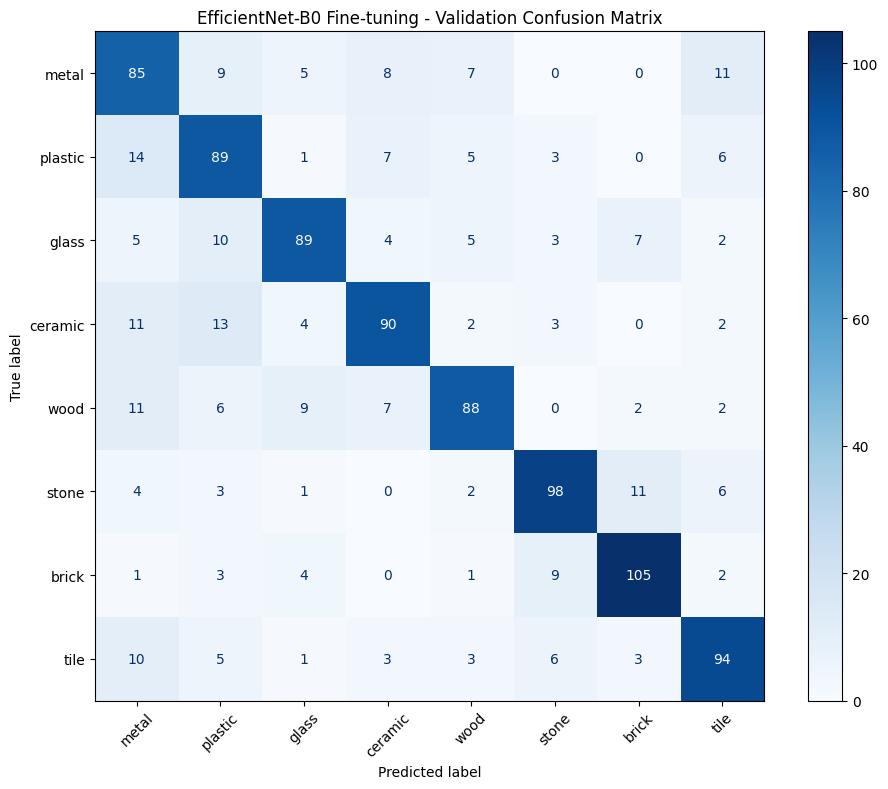

In [55]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm_final = confusion_matrix(
    y_true_final,
    y_pred_final,
    labels=list(range(8))
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=target_classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

plt.title(
    "EfficientNet-B0 Fine-tuning - Validation Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [56]:
RESULT_DIR = PROJECT_DIR / "results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Lưu classification report
df_final_report.to_csv(
    RESULT_DIR / "efficientnet_finetune_report.csv",
    encoding="utf-8-sig"
)

# Lưu confusion matrix dạng bảng
pd.DataFrame(
    cm_final,
    index=target_classes,
    columns=target_classes
).to_csv(
    RESULT_DIR / "efficientnet_finetune_confusion_matrix.csv",
    encoding="utf-8-sig"
)

# Lưu hình biểu đồ
fig.savefig(
    RESULT_DIR / "efficientnet_finetune_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

# Lưu dự đoán để đối chiếu với nhãn thật
df_predictions = pd.DataFrame({
    "true_label_id": y_true_final,
    "predicted_label_id": y_pred_final
})

df_predictions["true_material"] = (
    df_predictions["true_label_id"].map(
        dict(enumerate(target_classes))
    )
)

df_predictions["predicted_material"] = (
    df_predictions["predicted_label_id"].map(
        dict(enumerate(target_classes))
    )
)

df_predictions["correct"] = (
    df_predictions["true_label_id"] ==
    df_predictions["predicted_label_id"]
)

df_predictions.to_csv(
    RESULT_DIR / "efficientnet_finetune_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã lưu các báo cáo Validation!")

Đã lưu các báo cáo Validation!


In [57]:
import torch
import json
import hashlib
from pathlib import Path
from torchvision.models import efficientnet_b0
import torch.nn as nn

PROJECT_DIR = Path("/content/drive/MyDrive/nhận diện")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULT_DIR = PROJECT_DIR / "results"

RESULT_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = (
    CHECKPOINT_DIR / "efficientnet_b0_finetune_best.pt"
)

assert checkpoint_path.exists(), "Không tìm thấy checkpoint!"

ckpt = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert ckpt["epoch"] == 7
assert ckpt["class_names"] == target_classes

# Tính SHA-256 để ghi nhận phiên bản checkpoint
with open(checkpoint_path, "rb") as f:
    checkpoint_hash = hashlib.sha256(f.read()).hexdigest()

selection = {
    "project": "nhận diện",
    "selected_model": "EfficientNet-B0 Fine-tuning",
    "selected_epoch": int(ckpt["epoch"]),
    "validation_macro_f1": float(ckpt["val_macro_f1"]),
    "validation_accuracy": 0.738,
    "selection_metric": "Validation Macro-F1",
    "checkpoint_sha256": checkpoint_hash,
    "class_names": target_classes,
    "test_used_for_selection": False
}

with open(
    RESULT_DIR / "model_selection.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        selection, f,
        indent=4,
        ensure_ascii=False
    )

print("MODEL SELECTION LOCKED")
print("Model:", selection["selected_model"])
print("Epoch:", selection["selected_epoch"])
print("Validation Macro-F1:", selection["validation_macro_f1"])
print("SHA-256:", checkpoint_hash)

MODEL SELECTION LOCKED
Model: EfficientNet-B0 Fine-tuning
Epoch: 7
Validation Macro-F1: 0.7391795264672965
SHA-256: 864bfb8047d23d7829ad8a075decb486f561daa98e93bdcee9a78125b1d152f4


In [58]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

final_model = efficientnet_b0(weights=None)

in_features = final_model.classifier[-1].in_features

final_model.classifier[-1] = nn.Linear(
    in_features,
    8
)

final_model.load_state_dict(
    ckpt["model_state_dict"]
)

final_model = final_model.to(device)
final_model.eval()

print("FINAL MODEL READY")
print("Device:", device)
print("Classes:", target_classes)

FINAL MODEL READY
Device: cuda
Classes: ['metal', 'plastic', 'glass', 'ceramic', 'wood', 'stone', 'brick', 'tile']


In [59]:
from torch.utils.data import DataLoader

assert len(test_ds) == 2000
assert len(target_classes) == 8

# Kiểm tra tập Test sử dụng preprocessing xác định
assert test_ds.transform is eval_transform, (
    "Hãy kiểm tra lại preprocessing của tập Test."
)

final_test_loader = DataLoader(
    test_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("TEST SAMPLES:", len(test_ds))
print("TEST BATCHES:", len(final_test_loader))
print("FINAL TEST READY")

TEST SAMPLES: 2000
TEST BATCHES: 63
FINAL TEST READY


In [60]:
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_true_test = []
y_pred_test = []
y_conf_test = []

final_model.eval()

with torch.inference_mode():

    for images, labels in final_test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = final_model(images)

        probabilities = torch.softmax(
            outputs, dim=1
        )

        confidence, predictions = probabilities.max(
            dim=1
        )

        y_true_test.extend(labels.tolist())

        y_pred_test.extend(
            predictions.cpu().tolist()
        )

        y_conf_test.extend(
            confidence.cpu().tolist()
        )

# Kiểm tra đầy đủ dữ liệu
assert len(y_true_test) == 2000
assert len(y_pred_test) == 2000
assert len(y_conf_test) == 2000

assert set(y_true_test) == set(range(8))

# Tính các chỉ số
test_accuracy = accuracy_score(
    y_true_test, y_pred_test
)

test_macro_f1 = f1_score(
    y_true_test,
    y_pred_test,
    labels=list(range(8)),
    average="macro",
    zero_division=0
)

print("=" * 55)
print("NHẬN DIỆN - FINAL TEST RESULTS")
print("=" * 55)

print(f"Test Accuracy: {test_accuracy:.6f}")
print(f"Test Macro-F1: {test_macro_f1:.6f}")
print(
    "Correct Predictions:",
    sum(np.array(y_true_test) == np.array(y_pred_test))
)
print("Total Test Images:", len(y_true_test))

# Báo cáo chi tiết từng lớp
report_test = classification_report(
    y_true_test,
    y_pred_test,
    labels=list(range(8)),
    target_names=target_classes,
    output_dict=True,
    zero_division=0
)

df_test_report = pd.DataFrame(report_test).T

display(df_test_report.round(4))

NHẬN DIỆN - FINAL TEST RESULTS
Test Accuracy: 0.743500
Test Macro-F1: 0.743711
Correct Predictions: 1487
Total Test Images: 2000


,precision,recall,f1-score,support
metal,0.6478,0.6400,0.6439,250.0000
plastic,0.7500,0.7560,0.7530,250.0000
glass,0.7083,0.7480,0.7276,250.0000
ceramic,0.7558,0.7800,0.7677,250.0000
wood,0.6929,0.6680,0.6802,250.0000
stone,0.8039,0.8200,0.8119,250.0000
brick,0.8722,0.7920,0.8302,250.0000
tile,0.7266,0.7440,0.7352,250.0000
accuracy,0.7435,0.7435,0.7435,0.7435
macro avg,0.7447,0.7435,0.7437,2000.0000


In [61]:
from sklearn.metrics import confusion_matrix

df_test_predictions = pd.DataFrame({
    "test_index": range(len(y_true_test)),
    "true_label_id": y_true_test,
    "predicted_label_id": y_pred_test,
    "confidence": y_conf_test
})

df_test_predictions["true_material"] = [
    target_classes[i] for i in y_true_test
]

df_test_predictions["predicted_material"] = [
    target_classes[i] for i in y_pred_test
]

df_test_predictions["correct"] = (
    df_test_predictions["true_label_id"] ==
    df_test_predictions["predicted_label_id"]
)

df_test_predictions.to_csv(
    RESULT_DIR / "final_test_predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

df_test_report.to_csv(
    RESULT_DIR / "final_test_classification_report.csv",
    encoding="utf-8-sig"
)

cm_test = confusion_matrix(
    y_true_test,
    y_pred_test,
    labels=list(range(8))
)

pd.DataFrame(
    cm_test,
    index=target_classes,
    columns=target_classes
).to_csv(
    RESULT_DIR / "final_test_confusion_matrix.csv",
    encoding="utf-8-sig"
)

test_summary = {
    "model": "EfficientNet-B0 Fine-tuning",
    "checkpoint_sha256": checkpoint_hash,
    "test_samples": len(y_true_test),
    "accuracy": float(test_accuracy),
    "macro_f1": float(test_macro_f1)
}

with open(
    RESULT_DIR / "final_test_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(test_summary, f, indent=4)

print("FINAL TEST RESULTS SAVED!")
print("Folder:", RESULT_DIR)

FINAL TEST RESULTS SAVED!
Folder: /content/drive/MyDrive/nhận diện/results


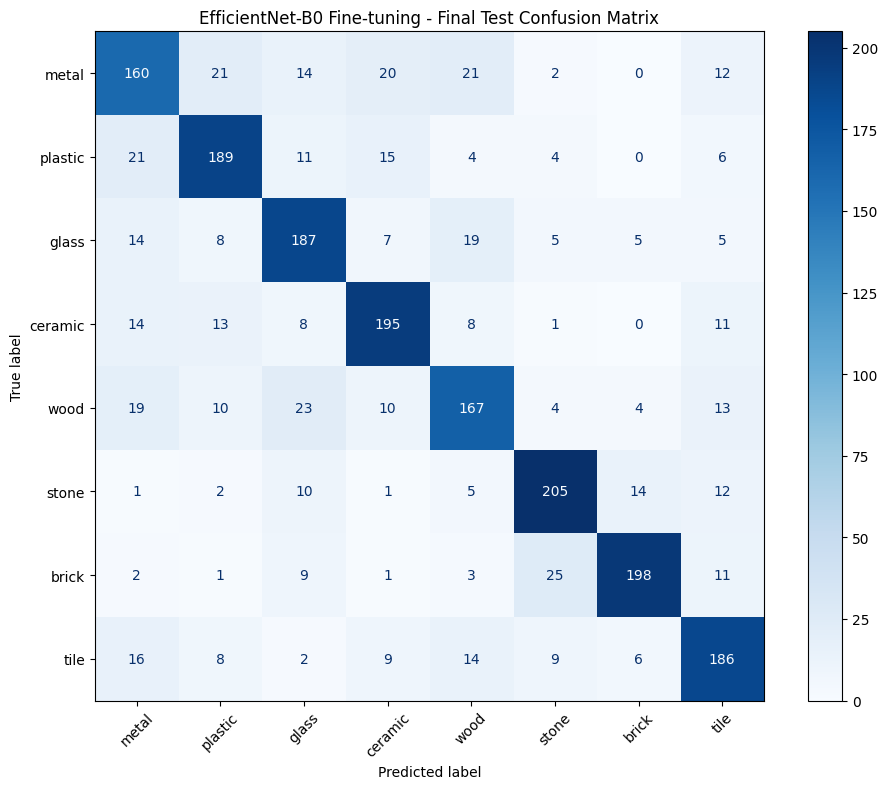

In [62]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=target_classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

ax.set_title(
    "EfficientNet-B0 Fine-tuning - Final Test Confusion Matrix"
)

plt.tight_layout()

fig.savefig(
    RESULT_DIR / "final_test_confusion_matrix.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

In [66]:
import pandas as pd
from pathlib import Path

RESULT_DIR = Path(
    "/content/drive/MyDrive/nhận diện/results"
)

file_path = RESULT_DIR / "final_test_predictions.csv"

assert file_path.exists(), (
    f"Không tìm thấy file: {file_path}"
)

df = pd.read_csv(file_path)

print("ĐỌC DỮ LIỆU THÀNH CÔNG!")
print("Tổng số ảnh Test:", len(df))
print("Số ảnh đúng:", df["correct"].sum())
print("Số ảnh sai:", (~df["correct"].astype(bool)).sum())

display(df.head())

ĐỌC DỮ LIỆU THÀNH CÔNG!
Tổng số ảnh Test: 2000
Số ảnh đúng: 1487
Số ảnh sai: 513


,test_index,true_label_id,predicted_label_id,confidence,true_material,predicted_material,correct
0,0,6,6,0.998498,brick,brick,True
1,1,6,2,0.387936,brick,glass,False
2,2,6,6,0.999906,brick,brick,True
3,3,6,5,0.993922,brick,stone,False
4,4,6,6,0.537246,brick,brick,True


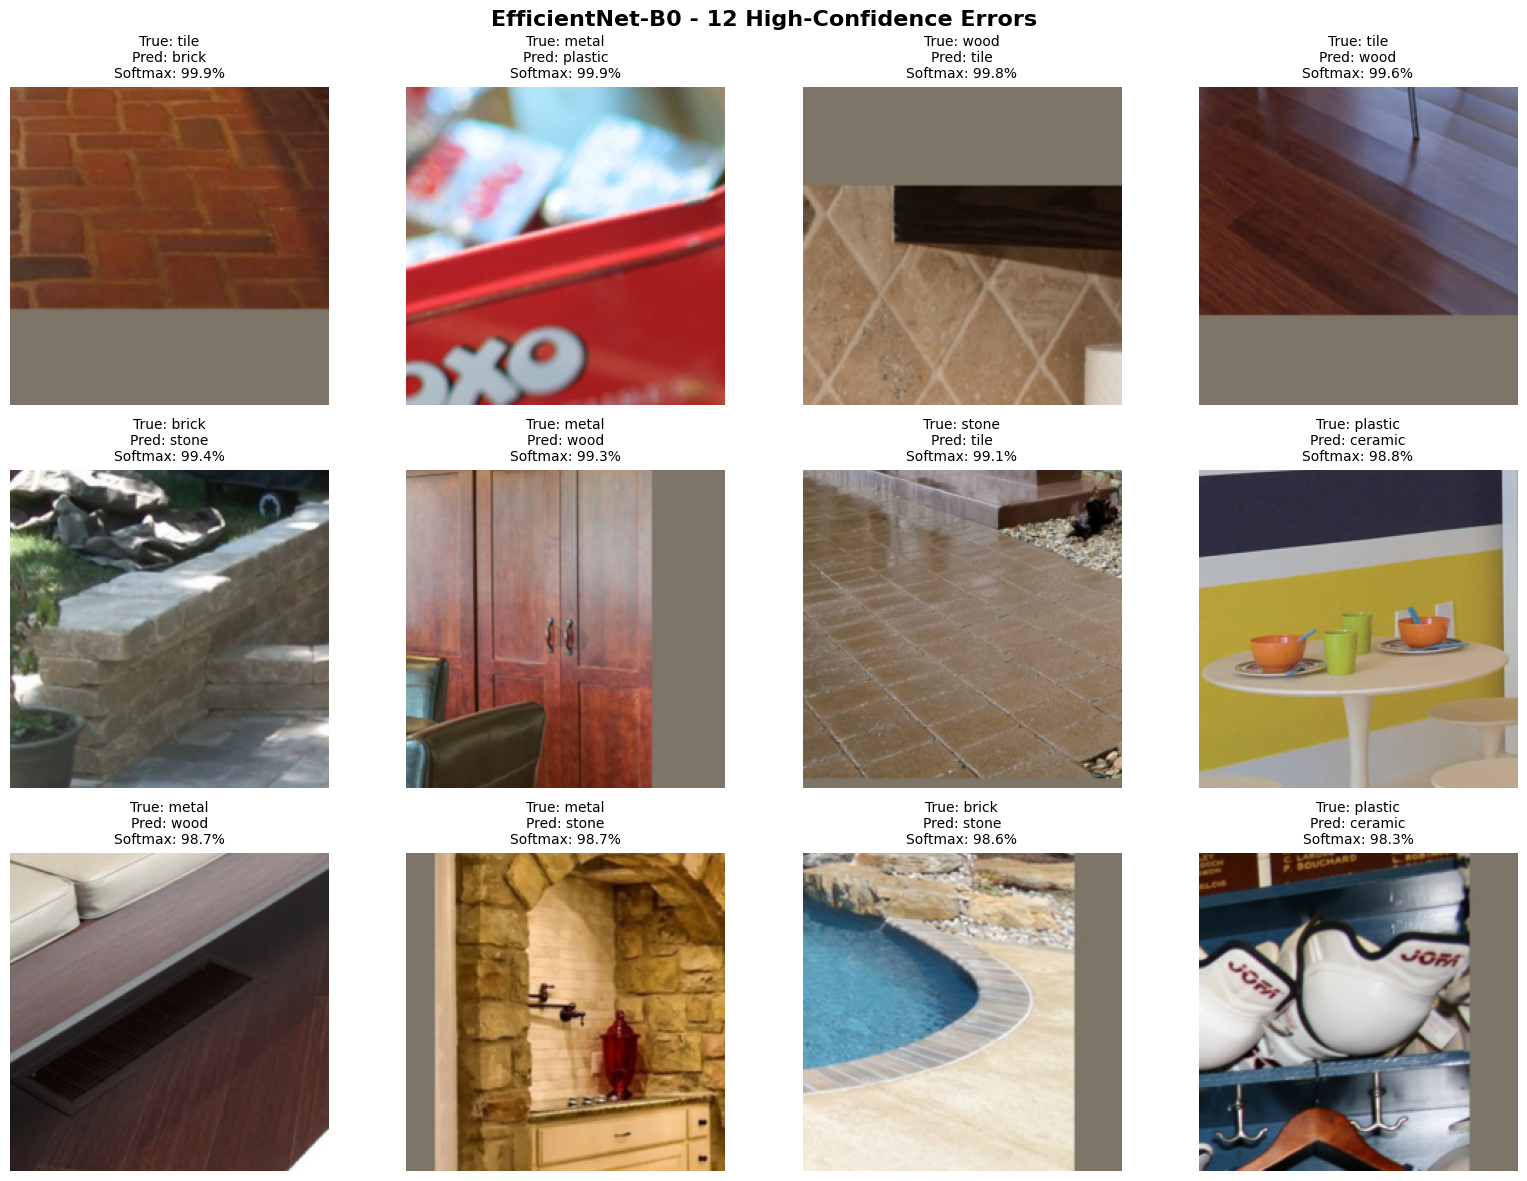

ĐÃ LƯU HÌNH THÀNH CÔNG!


In [67]:
import matplotlib.pyplot as plt
import numpy as np

# Chọn 12 ảnh dự đoán sai có Softmax cao nhất
wrong = df[
    df["true_label_id"] != df["predicted_label_id"]
].sort_values(
    "confidence",
    ascending=False
).head(12)

# Kiểm tra dữ liệu
assert len(test_ds) == 2000
assert len(wrong) == 12
assert len(target_classes) == 8

# Thông số chuẩn hóa ImageNet
mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for ax, (_, row) in zip(axes.flat, wrong.iterrows()):

    image_index = int(row["test_index"])

    image_tensor, real_label = test_ds[image_index]

    assert real_label == int(row["true_label_id"])

    # Chuyển tensor về ảnh hiển thị
    image = image_tensor.cpu().numpy()

    image = image * std + mean
    image = np.clip(image, 0, 1)
    image = np.transpose(image, (1, 2, 0))

    ax.imshow(image)

    ax.set_title(
        f"True: {target_classes[real_label]}\n"
        f"Pred: {row['predicted_material']}\n"
        f"Softmax: {row['confidence']:.1%}",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "EfficientNet-B0 - 12 High-Confidence Errors",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    RESULT_DIR / "final_test_high_confidence_errors.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("ĐÃ LƯU HÌNH THÀNH CÔNG!")

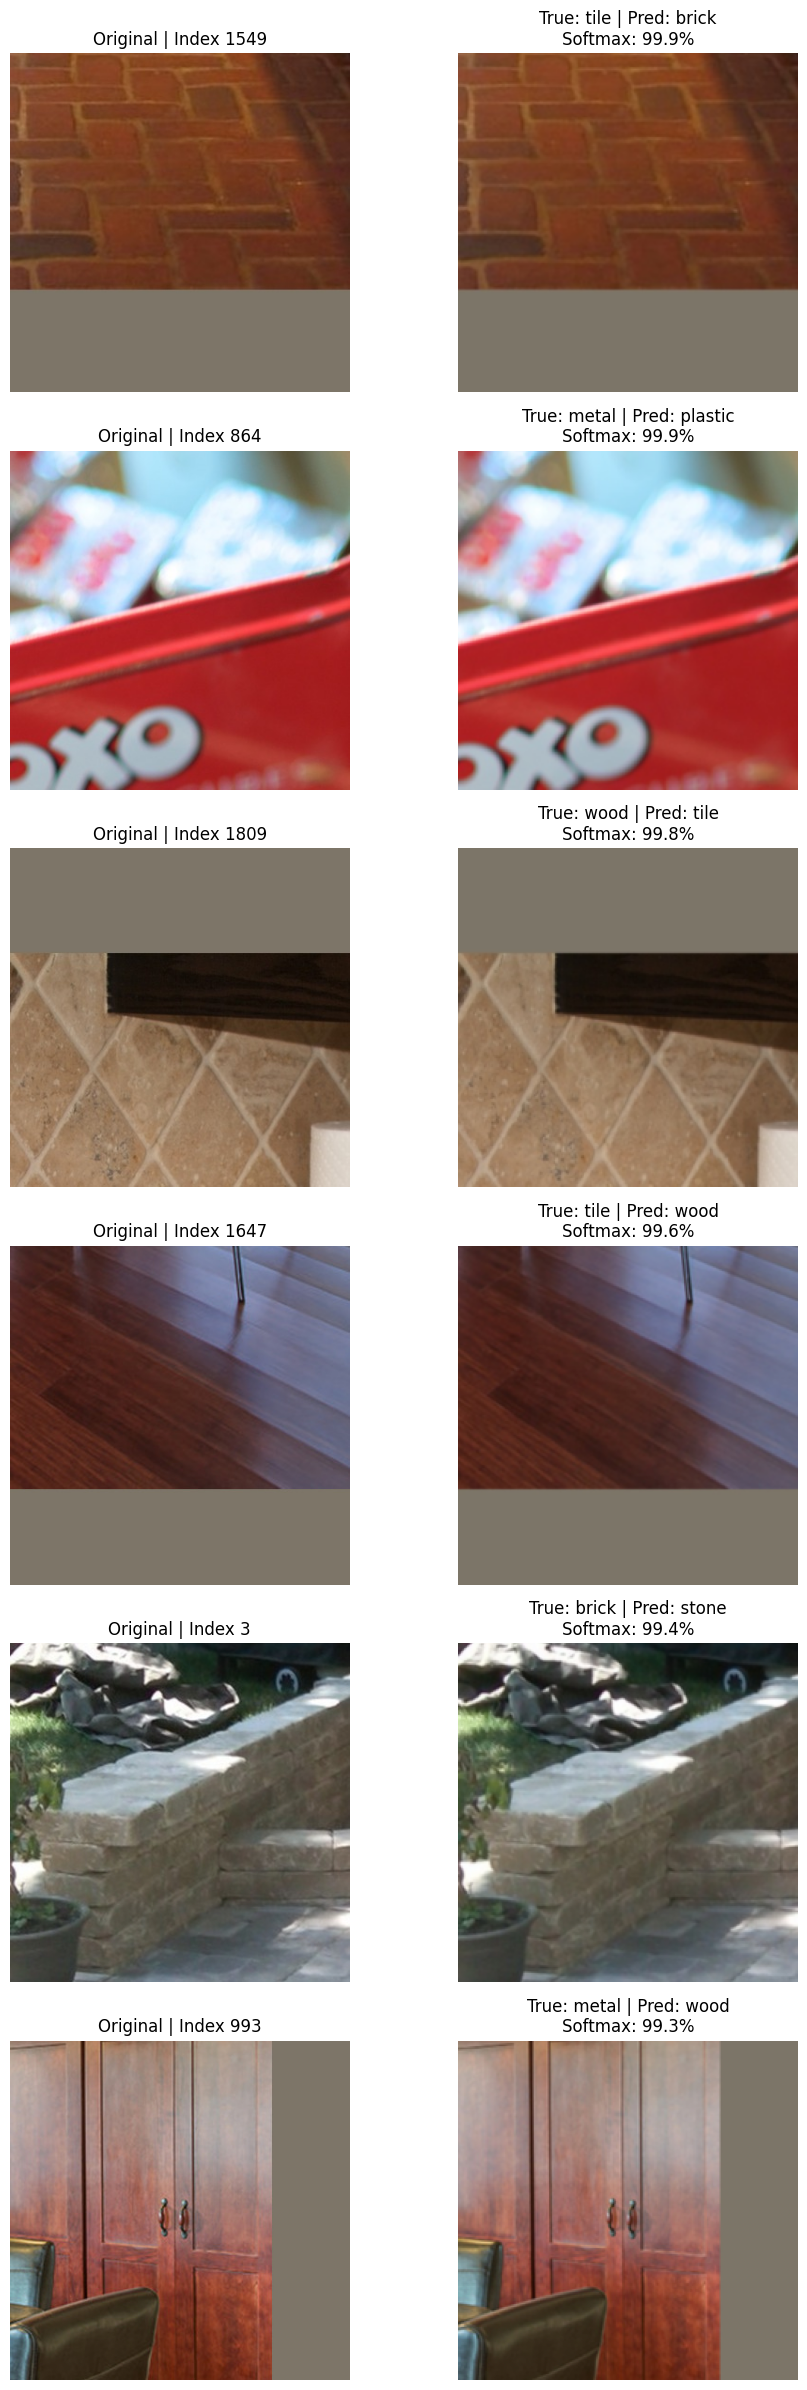

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RESULT_DIR = Path(
    "/content/drive/MyDrive/nhận diện/results"
)

df = pd.read_csv(
    RESULT_DIR / "final_test_predictions.csv"
)

wrong = df[
    df["true_label_id"] != df["predicted_label_id"]
].sort_values("confidence", ascending=False).head(6)

assert len(test_ds) == 2000
assert hasattr(test_ds, "data")

mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)

fig, axes = plt.subplots(6, 2, figsize=(10, 24))

for i, (_, row) in enumerate(wrong.iterrows()):

    idx = int(row["test_index"])

    # Ảnh RGB gốc từ tập Test đã chọn
    raw_sample = test_ds.data[idx]
    raw_image = raw_sample["image"].convert("RGB")

    # Ảnh đã preprocessing
    image_tensor, true_label = test_ds[idx]

    assert true_label == int(row["true_label_id"])

    image = image_tensor.cpu().numpy()
    image = image * std + mean
    image = np.transpose(np.clip(image, 0, 1), (1, 2, 0))

    axes[i, 0].imshow(raw_image)
    axes[i, 0].set_title(f"Original | Index {idx}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(image)
    axes[i, 1].set_title(
        f"True: {target_classes[true_label]} | "
        f"Pred: {row['predicted_material']}\n"
        f"Softmax: {row['confidence']:.1%}"
    )
    axes[i, 1].axis("off")

plt.tight_layout()

fig.savefig(
    RESULT_DIR / "original_vs_preprocessed_errors.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

VALIDATION CALIBRATION REPORT
Validation Accuracy: 0.738
Mean Softmax Confidence: 0.7865395
ECE (10 bins): 0.061368
Errors with confidence >= 90%: 37


,bin,samples,avg_confidence,accuracy
0,2,4,0.2692,0.2500
1,3,28,0.3533,0.3571
2,4,103,0.4533,0.5146
3,5,84,0.5491,0.5357
4,6,103,0.6465,0.5825
5,7,115,0.7469,0.6609
6,8,134,0.8550,0.7537
7,9,429,0.9690,0.9138


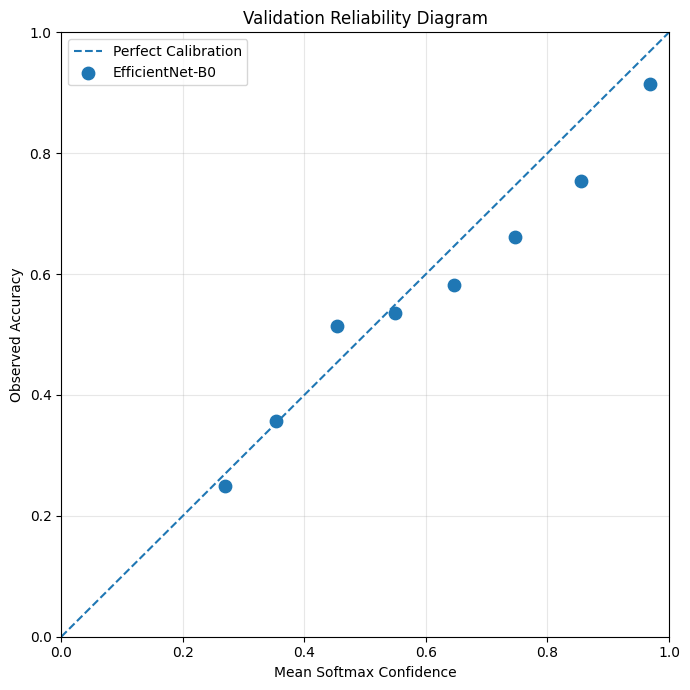

In [69]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

final_model.eval()

all_conf = []
all_correct = []

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(device)

        logits = final_model(images)

        probs = torch.softmax(logits, dim=1)

        confidence, prediction = probs.max(dim=1)

        all_conf.extend(confidence.cpu().numpy())
        all_correct.extend(
            (prediction.cpu() == labels).numpy()
        )

all_conf = np.asarray(all_conf)
all_correct = np.asarray(all_correct, dtype=float)

assert len(all_conf) == 1000

# Chia Softmax confidence thành 10 khoảng
edges = np.linspace(0, 1, 11)
bin_ids = np.clip(
    np.digitize(all_conf, edges, right=True) - 1,
    0, 9
)

rows = []

for b in range(10):

    mask = bin_ids == b

    if not mask.any():
        continue

    rows.append({
        "bin": b,
        "samples": int(mask.sum()),
        "avg_confidence": float(all_conf[mask].mean()),
        "accuracy": float(all_correct[mask].mean())
    })

calibration_df = pd.DataFrame(rows)

ece = (
    calibration_df["samples"]
    / len(all_conf)
    * abs(
        calibration_df["accuracy"]
        - calibration_df["avg_confidence"]
    )
).sum()

print("VALIDATION CALIBRATION REPORT")
print("=" * 50)

print("Validation Accuracy:", all_correct.mean())
print("Mean Softmax Confidence:", all_conf.mean())
print("ECE (10 bins):", round(ece, 6))

print(
    "Errors with confidence >= 90%:",
    int(((all_correct == 0) & (all_conf >= 0.90)).sum())
)

display(calibration_df.round(4))

# Reliability Diagram
fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    [0, 1], [0, 1],
    "--",
    label="Perfect Calibration"
)

ax.scatter(
    calibration_df["avg_confidence"],
    calibration_df["accuracy"],
    s=80,
    label="EfficientNet-B0"
)

ax.set_xlabel("Mean Softmax Confidence")
ax.set_ylabel("Observed Accuracy")
ax.set_title("Validation Reliability Diagram")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

fig.savefig(
    RESULT_DIR / "validation_reliability_diagram.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

calibration_df.to_csv(
    RESULT_DIR / "validation_calibration.csv",
    index=False
)

In [70]:
import numpy as np
import torch
import json
from pathlib import Path

from scipy.optimize import minimize_scalar
from scipy.special import softmax, logsumexp
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

RESULT_DIR = Path(
    "/content/drive/MyDrive/nhận diện/results"
)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Thu thập logits trên Validation
final_model.eval()

logits_list = []
labels_list = []

with torch.inference_mode():
    for images, labels in val_loader:
        images = images.to(device)

        logits = final_model(images)

        logits_list.append(logits.cpu().numpy())
        labels_list.append(labels.numpy())

logits = np.concatenate(logits_list)
labels = np.concatenate(labels_list).astype(int)

assert logits.shape == (1000, 8)
assert labels.shape == (1000,)

# 2. Chia tập để thử hiệu chỉnh
indices = np.arange(len(labels))

cal_idx, check_idx = train_test_split(
    indices,
    test_size=0.5,
    random_state=42,
    stratify=labels
)

# 3. Hàm Negative Log-Likelihood
def nll_at_temperature(T, indices):
    scaled = logits[indices] / T
    true_logits = scaled[
        np.arange(len(indices)),
        labels[indices]
    ]

    return float(
        np.mean(logsumexp(scaled, axis=1) - true_logits)
    )

# 4. Tìm Temperature tối ưu theo NLL
result = minimize_scalar(
    lambda T: nll_at_temperature(T, cal_idx),
    bounds=(0.1, 10.0),
    method="bounded"
)

assert result.success

best_T = float(result.x)

# 5. Tính ECE
def compute_ece(probs, true_labels, n_bins=10):

    confidence = probs.max(axis=1)
    predictions = probs.argmax(axis=1)

    correct = (predictions == true_labels)

    bins = np.minimum(
        (confidence * n_bins).astype(int),
        n_bins - 1
    )

    ece = 0.0

    for b in range(n_bins):
        mask = bins == b

        if not np.any(mask):
            continue

        avg_conf = confidence[mask].mean()
        avg_acc = correct[mask].mean()

        ece += mask.mean() * abs(avg_conf - avg_acc)

    return float(ece)

# 6. So sánh trên 500 ảnh không dùng tìm T
check_logits = logits[check_idx]
check_labels = labels[check_idx]

probs_before = softmax(check_logits, axis=1)
probs_after = softmax(check_logits / best_T, axis=1)

ece_before = compute_ece(probs_before, check_labels)
ece_after = compute_ece(probs_after, check_labels)

nll_before = nll_at_temperature(1.0, check_idx)
nll_after = nll_at_temperature(best_T, check_idx)

accuracy_before = accuracy_score(
    check_labels,
    probs_before.argmax(axis=1)
)

accuracy_after = accuracy_score(
    check_labels,
    probs_after.argmax(axis=1)
)

print("=" * 55)
print("TEMPERATURE SCALING RESULTS")
print("=" * 55)

print(f"Optimal Temperature: {best_T:.4f}")

print(f"ECE Before: {ece_before:.6f}")
print(f"ECE After : {ece_after:.6f}")

print(f"NLL Before: {nll_before:.6f}")
print(f"NLL After : {nll_after:.6f}")

print(f"Accuracy Before: {accuracy_before:.4f}")
print(f"Accuracy After : {accuracy_after:.4f}")

assert np.array_equal(
    probs_before.argmax(axis=1),
    probs_after.argmax(axis=1)
)

# 7. Lưu kết quả thăm dò
calibration_result = {
    "method": "temperature_scaling",
    "temperature": best_T,
    "calibration_samples": len(cal_idx),
    "check_samples": len(check_idx),
    "ece_before": ece_before,
    "ece_after": ece_after,
    "nll_before": nll_before,
    "nll_after": nll_after,
    "accuracy_before": accuracy_before,
    "accuracy_after": accuracy_after,
    "status": "exploratory_validation_only"
}

with open(
    RESULT_DIR / "temperature_scaling_experiment.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        calibration_result,
        f,
        ensure_ascii=False,
        indent=4
    )

print("Đã lưu kết quả thí nghiệm!")

TEMPERATURE SCALING RESULTS
Optimal Temperature: 1.2519
ECE Before: 0.079205
ECE After : 0.050402
NLL Before: 0.800231
NLL After : 0.776670
Accuracy Before: 0.7400
Accuracy After : 0.7400
Đã lưu kết quả thí nghiệm!


In [71]:
import json
import shutil
import hashlib
import torch

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/nhận diện")

SOURCE_MODEL = (
    PROJECT_DIR
    / "checkpoints"
    / "efficientnet_b0_finetune_best.pt"
)

DEPLOY_DIR = PROJECT_DIR / "deployment"
DEPLOY_DIR.mkdir(parents=True, exist_ok=True)

assert SOURCE_MODEL.exists(), "Không tìm thấy checkpoint!"

# Kiểm tra checkpoint chính thức
ckpt = torch.load(
    SOURCE_MODEL,
    map_location="cpu",
    weights_only=True
)

assert ckpt["epoch"] == 7

classes = ckpt["class_names"]

assert len(classes) == 8
assert len(set(classes)) == 8

# Sao chép checkpoint, không thay đổi trọng số
DEPLOY_MODEL = DEPLOY_DIR / "material_model.pt"

shutil.copy2(
    SOURCE_MODEL,
    DEPLOY_MODEL
)

# Ghi thông tin checkpoint
sha256 = hashlib.file_digest(
    open(DEPLOY_MODEL, "rb"),
    "sha256"
).hexdigest()

# Temperature được ghi nhận là cấu hình thử nghiệm
config = {
    "project": "nhận diện",
    "model": "efficientnet_b0",
    "model_file": "material_model.pt",

    "model_epoch": 7,
    "model_sha256": sha256,

    "num_classes": 8,
    "class_names": classes,

    "image_size": [224, 224],

    "normalization": {
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225]
    },

    "temperature": 1.2519,
    "temperature_status": "exploratory",

    "test_accuracy": 0.7435,
    "test_macro_f1": 0.743711,

    "confidence_note": (
        "Calibrated Softmax is not a guarantee "
        "that the prediction is correct."
    )
}

CONFIG_PATH = DEPLOY_DIR / "model_config.json"

with open(
    CONFIG_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        config,
        f,
        indent=4,
        ensure_ascii=False
    )

print("=" * 55)
print("DEPLOYMENT PACKAGE CREATED")
print("=" * 55)

print("Model:", DEPLOY_MODEL)
print("Config:", CONFIG_PATH)
print("Classes:", classes)
print("Temperature:", config["temperature"])

print("\nREADY FOR WEB DEVELOPMENT")

DEPLOYMENT PACKAGE CREATED
Model: /content/drive/MyDrive/nhận diện/deployment/material_model.pt
Config: /content/drive/MyDrive/nhận diện/deployment/model_config.json
Classes: ['metal', 'plastic', 'glass', 'ceramic', 'wood', 'stone', 'brick', 'tile']
Temperature: 1.2519

READY FOR WEB DEVELOPMENT


In [72]:
hasher = hashlib.sha256()

with open(DEPLOY_MODEL, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        hasher.update(chunk)

sha256 = hasher.hexdigest()

In [74]:
import json
import hashlib
import torch
from pathlib import Path

DEPLOY_DIR = Path(
    "/content/drive/MyDrive/nhận diện/deployment"
)

model_path = DEPLOY_DIR / "material_model.pt"
config_path = DEPLOY_DIR / "model_config.json"

assert model_path.exists(), "Thiếu material_model.pt"
assert config_path.exists(), "Thiếu model_config.json"

# Tính lại SHA-256
hasher = hashlib.sha256()

with open(model_path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        hasher.update(chunk)

sha256 = hasher.hexdigest()

# Kiểm tra checkpoint thật
ckpt = torch.load(
    model_path,
    map_location="cpu",
    weights_only=True
)

assert int(ckpt["epoch"]) == 7

expected_classes = [
    "metal", "plastic", "glass", "ceramic",
    "wood", "stone", "brick", "tile"
]

assert list(ckpt["class_names"]) == expected_classes

# Đọc cấu hình cũ
with open(config_path, "r", encoding="utf-8") as f:
    config = json.load(f)

# Đồng bộ cấu hình với checkpoint
config["model"] = "efficientnet_b0"
config["model_file"] = "material_model.pt"
config["model_epoch"] = 7
config["model_sha256"] = sha256
config["class_names"] = expected_classes
config["num_classes"] = 8
config["image_size"] = [224, 224]
config["resize_mode"] = "resize_exact"

config["normalization"] = {
    "mean": [0.485, 0.456, 0.406],
    "std": [0.229, 0.224, 0.225]
}

# Dùng Temperature thực nghiệm đã lưu
cal_path = (
    DEPLOY_DIR.parent
    / "results"
    / "temperature_scaling_experiment.json"
)

assert cal_path.exists(), "Thiếu kết quả Temperature Scaling"

with open(cal_path, "r", encoding="utf-8") as f:
    calibration = json.load(f)

config["temperature"] = float(calibration["temperature"])
config["temperature_status"] = "exploratory_validation_only"

# Lưu cấu hình đã kiểm tra
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=4)

print("=" * 55)
print("NHẬN DIỆN - DEPLOYMENT VERIFICATION")
print("=" * 55)

print("MODEL:", config["model"])
print("EPOCH:", config["model_epoch"])
print("CLASSES:", config["class_names"])
print("TEMPERATURE:", config["temperature"])
print("SHA-256:", sha256)
print("MODEL SIZE:", round(model_path.stat().st_size / 1024**2, 2), "MB")

print("\nDEPLOYMENT VERIFIED!")

NHẬN DIỆN - DEPLOYMENT VERIFICATION
MODEL: efficientnet_b0
EPOCH: 7
CLASSES: ['metal', 'plastic', 'glass', 'ceramic', 'wood', 'stone', 'brick', 'tile']
TEMPERATURE: 1.2519271102581124
SHA-256: 864bfb8047d23d7829ad8a075decb486f561daa98e93bdcee9a78125b1d152f4
MODEL SIZE: 15.61 MB

DEPLOYMENT VERIFIED!
